# ✈️ Exploratory Data Analysis — Flight Price Prediction

This notebook adapts the reference EDA workflow to our flight-price dataset.

**Goal:** understand the training/test data, identify data-quality issues, explore how each feature relates to `price`, and identify useful feature-engineering ideas.

> Place `train.csv`, `test.csv`, and `sample_submission.csv` in the Colab working directory before running. This notebook explores the data; it does not train a model or create a Kaggle submission.

File uploads

In [1]:
from google.colab import files
upoaded = files.upload()

Saving submission.csv to submission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv


## 1. Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 6)

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("submission.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)
display(train.head())

Train shape: (18076, 12)
Test shape: (4520, 11)
Sample submission shape: (4520, 2)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146


## 2. Data overview

In [3]:
print("Training columns:", train.columns.tolist())
print("\nTest columns:", test.columns.tolist())

print("\nTraining data info:")
train.info()

print("\nTest data info:")
test.info()

display(train.describe(include="all").T)

Training columns: ['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left', 'price']

Test columns: ['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left']

Training data info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18076 entries, 0 to 18075
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                18076 non-null  int64  
 1   airline           18076 non-null  object 
 2   flight            18076 non-null  object 
 3   source_city       18076 non-null  object 
 4   departure_time    18076 non-null  object 
 5   stops             18076 non-null  object 
 6   arrival_time      18076 non-null  object 
 7   destination_city  18076 non-null  object 
 8   flight_class      18076 non-null  object 
 9   duration    

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,18076.0,NaN,NaN,NaN,11308.626189,6526.337957,0.0,5668.75,11329.5,16949.5,22595.0
airline,18076,7,Alaska_Airlines,4554,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight,18076,1123,AA 6279,183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_city,18076,5,Los Angeles,4561,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departure_time,18076,6,Morning,5144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stops,18076,3,zero,13559,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_time,18076,6,Afternoon,4785,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination_city,18076,5,Los Angeles,4533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight_class,18076,2,Economy,10711,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,18076.0,NaN,NaN,NaN,2.746853,2.947519,0.87,1.47,1.63,2.0,28.65


### Missing values and duplicates

In [4]:
missing_train = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_pct": (train.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_train)

missing_test = pd.DataFrame({
    "missing_count": test.isna().sum(),
    "missing_pct": (test.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_test)

print("Duplicate training rows:", train.duplicated().sum())
if "id" in train.columns:
    print("Duplicate train IDs:", train["id"].duplicated().sum())
if "id" in test.columns:
    print("Duplicate test IDs:", test["id"].duplicated().sum())

,missing_count,missing_pct
id,0,0.0
airline,0,0.0
flight,0,0.0
source_city,0,0.0
departure_time,0,0.0
stops,0,0.0
arrival_time,0,0.0
destination_city,0,0.0
flight_class,0,0.0
duration,0,0.0


,missing_count,missing_pct
id,0,0.0
airline,0,0.0
flight,0,0.0
source_city,0,0.0
departure_time,0,0.0
stops,0,0.0
arrival_time,0,0.0
destination_city,0,0.0
flight_class,0,0.0
duration,0,0.0


Duplicate training rows: 0
Duplicate train IDs: 0
Duplicate test IDs: 0


**How to interpret this section**
- `shape` tells us the number of rows and columns.
- `info()` shows data types and non-null counts.
- Missing-value percentages show whether imputation may be needed.
- Duplicate IDs are worth investigating because `id` is intended to identify rows. Duplicate complete rows are a separate check.

## 3. Univariate analysis

### 3.1 Numeric feature distributions

Numeric columns: ['id', 'duration', 'days_left', 'price']


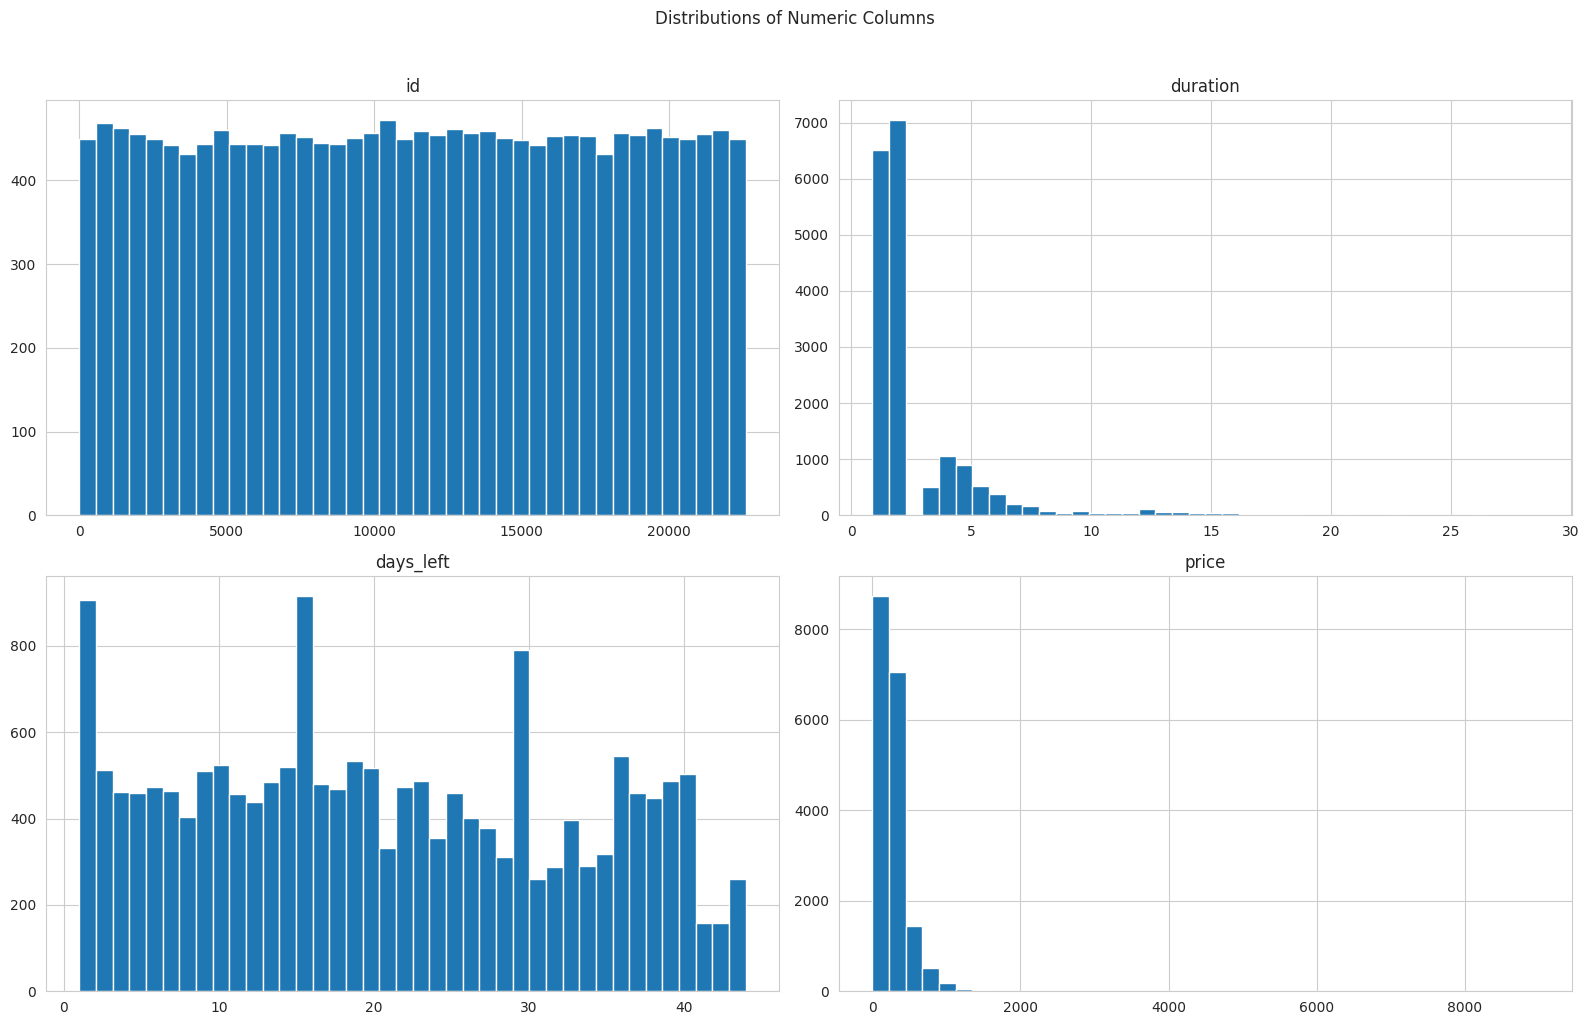

In [5]:
numeric_cols = train.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:", numeric_cols)

train[numeric_cols].hist(bins=40, figsize=(16, 10))
plt.suptitle("Distributions of Numeric Columns", y=1.02)
plt.tight_layout()
plt.show()

Histograms show the shape of each numeric column. `price` is the target, while columns such as `duration` and `days_left` are predictors. Strong skew or unusual spikes can guide later transformations, but do not automatically mean the data is wrong.

### 3.2 Boxplots for numeric columns

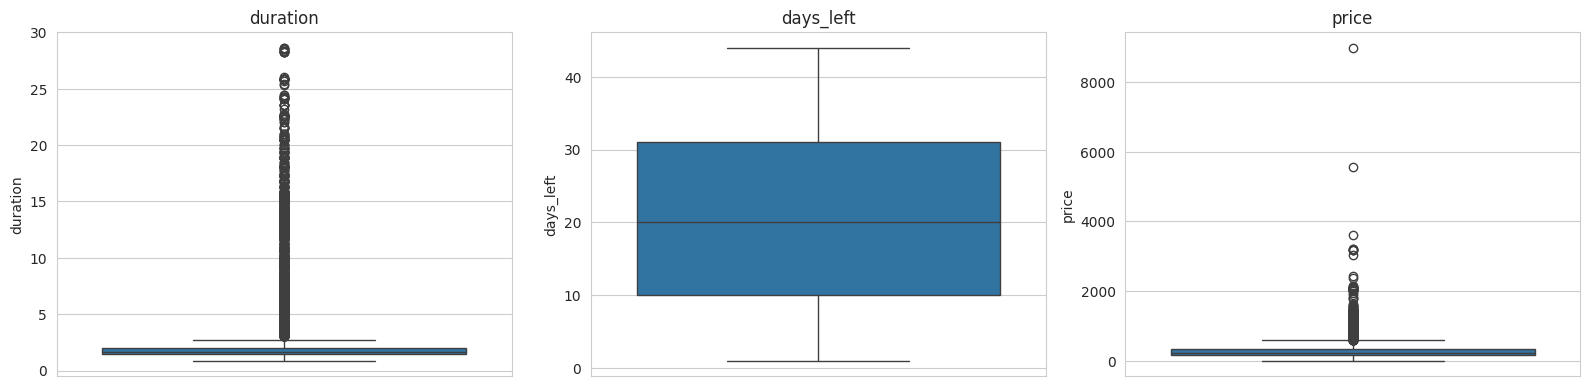

In [6]:
plot_cols = [c for c in numeric_cols if c != "id"]
ncols = 3
nrows = int(np.ceil(len(plot_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows))
axes = np.array(axes).reshape(-1)

for i, col in enumerate(plot_cols):
    sns.boxplot(y=train[col], ax=axes[i])
    axes[i].set_title(col)

for j in range(len(plot_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Boxplots flag potential outliers using quartiles. A flagged value is not necessarily an error: a long flight duration or expensive business-class ticket may be legitimate.

### 3.3 Categorical feature counts

Categorical columns: ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class']

airline: 7 distinct values


,count
airline,
Alaska_Airlines,4554
United,4058
Southwest,3895
Delta,2972
American_Airlines,1797
Frontier,799
Southern_Airways_Express,1


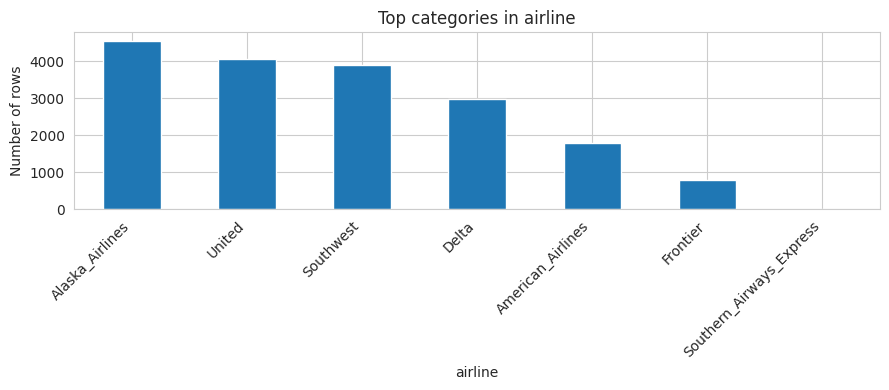


flight: 1123 distinct values


,count
flight,
AA 6279,183
DL 3716,156
DL 3883,149
AA 1358,144
DL 4087,141
DL 3755,136
AA 6278,130
DL 3712,130
AA 6277,129


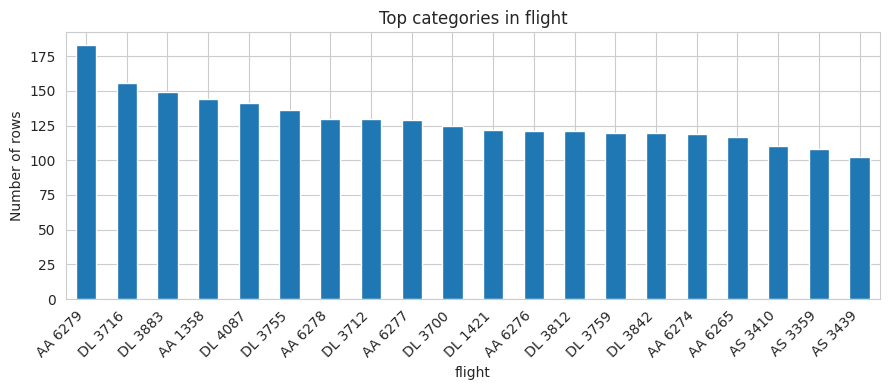


source_city: 5 distinct values


,count
source_city,
Los Angeles,4561
San Francisco,4086
San Diego,3691
Sacramento,3521
San Jose,2217


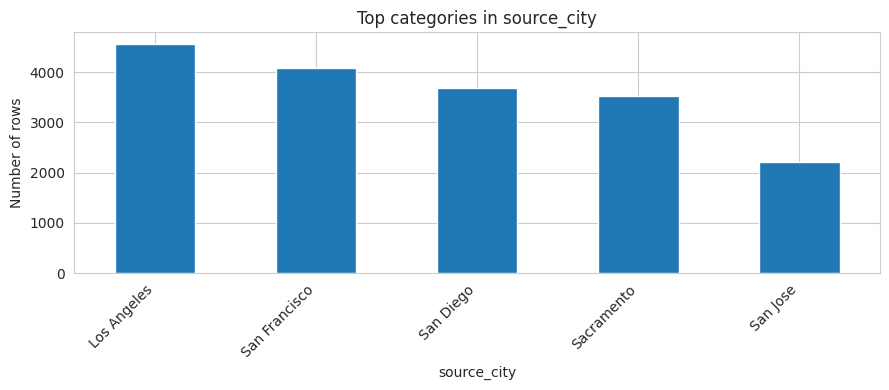


departure_time: 6 distinct values


,count
departure_time,
Morning,5144
Evening,4436
Afternoon,3893
Early_Morning,2820
Night,1777
Late_Night,6


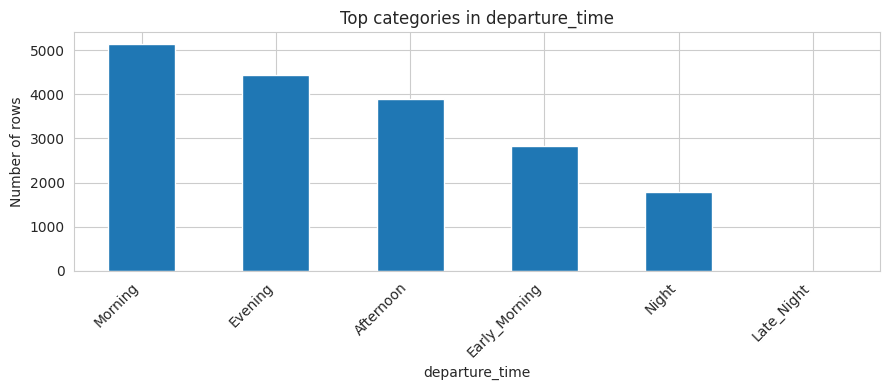


stops: 3 distinct values


,count
stops,
zero,13559
one,4324
two_or_more,193


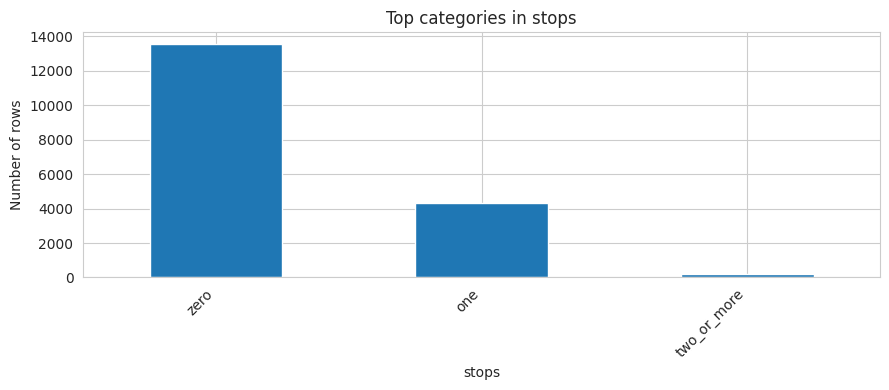


arrival_time: 6 distinct values


,count
arrival_time,
Afternoon,4785
Evening,4549
Morning,4364
Night,3701
Early_Morning,525
Late_Night,152


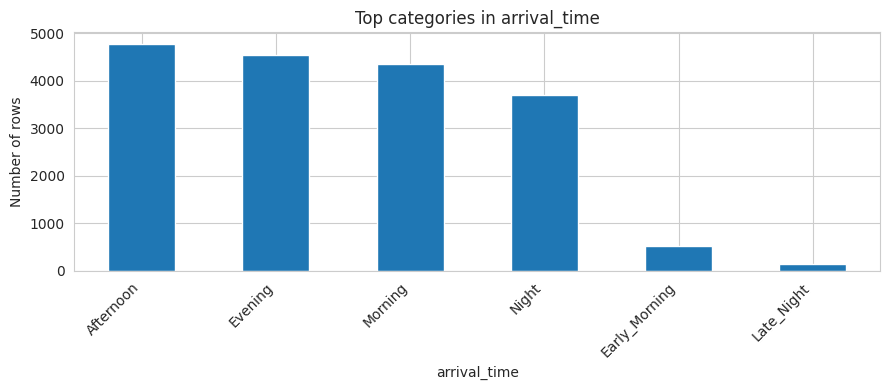


destination_city: 5 distinct values


,count
destination_city,
Los Angeles,4533
San Francisco,4073
San Diego,3743
Sacramento,3303
San Jose,2424


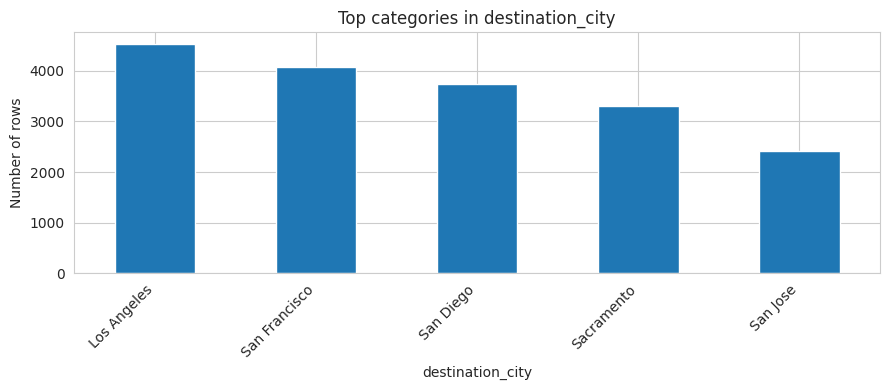


flight_class: 2 distinct values


,count
flight_class,
Economy,10711
Business,7365


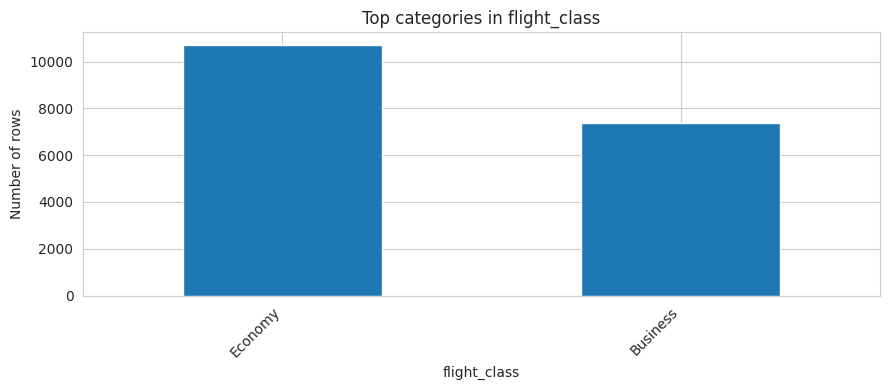

In [7]:
categorical_cols = train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
categorical_cols = [c for c in categorical_cols if c != "price"]
print("Categorical columns:", categorical_cols)

for col in categorical_cols:
    print(f"\n{col}: {train[col].nunique(dropna=False)} distinct values")
    display(train[col].value_counts(dropna=False).head(20).rename("count").to_frame())

    plt.figure(figsize=(9, 4))
    train[col].astype("string").value_counts().head(20).plot(kind="bar")
    plt.title(f"Top categories in {col}")
    plt.ylabel("Number of rows")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### 3.4 Target variable: price

,price
count,18076.000000
mean,280.264550
std,221.965133
min,0.000000
25%,157.000000
50%,234.000000
75%,336.000000
max,8996.000000


Unique prices: 768
Missing prices: 0
Zero/negative prices: 25


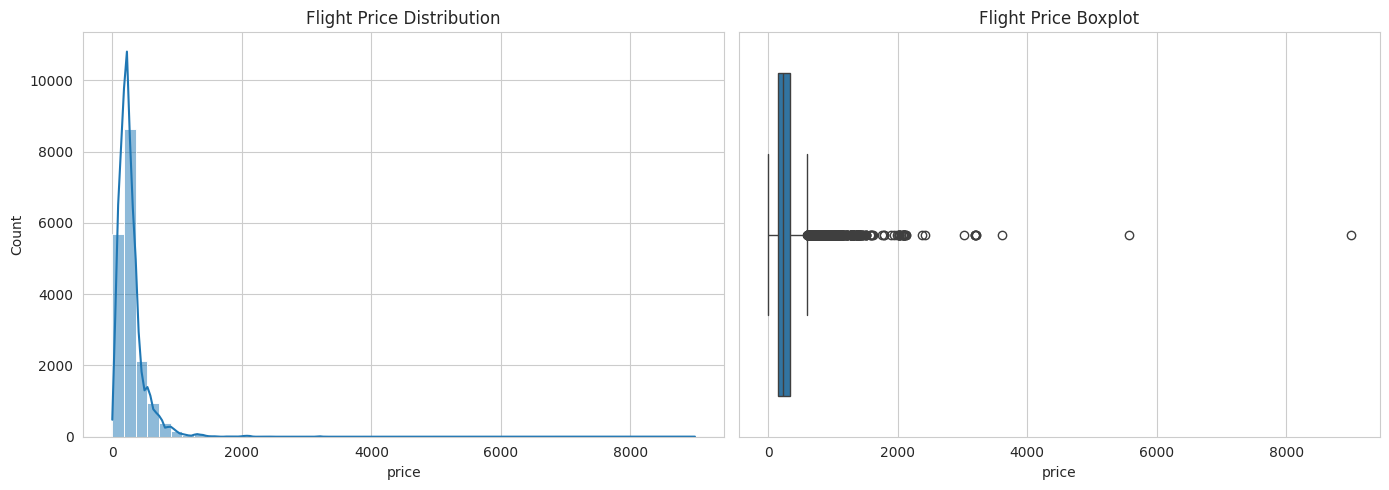

Skewness of price: 7.06991758878095


In [8]:
display(train["price"].describe())
print("Unique prices:", train["price"].nunique())
print("Missing prices:", train["price"].isna().sum())
print("Zero/negative prices:", (train["price"] <= 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train["price"].dropna(), bins=50, kde=True, ax=axes[0])
axes[0].set_title("Flight Price Distribution")
sns.boxplot(x=train["price"], ax=axes[1])
axes[1].set_title("Flight Price Boxplot")
plt.tight_layout()
plt.show()

print("Skewness of price:", train["price"].skew())

Check whether prices are skewed and whether there are unusually high or low values. We should investigate suspicious values rather than delete them automatically. This is a regression problem, so ordinary classification accuracy is generally not the appropriate metric.

## 4. Bivariate analysis: features vs price

### 4.1 Numeric feature correlations

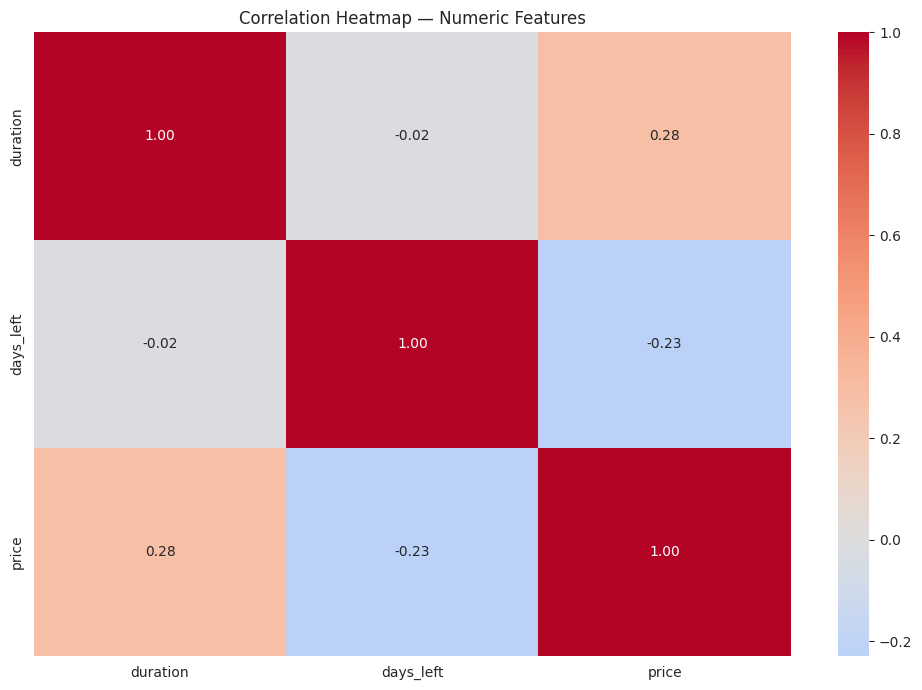

Correlation with price:


,correlation_with_price
duration,0.281357
days_left,-0.229164


In [9]:
# Correlation only applies to numeric columns.
corr_cols = [c for c in numeric_cols if c != "id"]
corr = train[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — Numeric Features")
plt.tight_layout()
plt.show()

if "price" in corr.columns:
    print("Correlation with price:")
    display(corr["price"].drop("price").sort_values(key=lambda s: s.abs(), ascending=False).to_frame("correlation_with_price"))

Correlation measures linear association, not causation. A low numeric correlation does not mean a feature is useless, especially for categorical variables or nonlinear relationships.

### 4.2 Numeric feature vs price plots

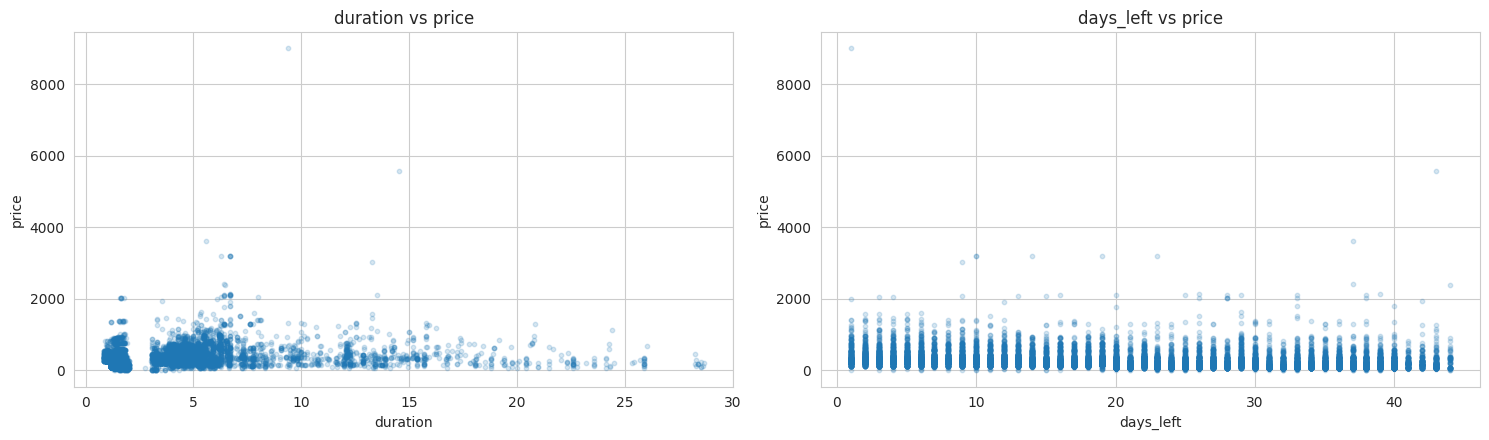

In [10]:
numeric_predictors = [c for c in numeric_cols if c not in ["price", "id"]]
if numeric_predictors:
    ncols = 2
    nrows = int(np.ceil(len(numeric_predictors) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(numeric_predictors):
        axes[i].scatter(train[col], train["price"], alpha=0.18, s=10)
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("price")
        axes[i].set_title(f"{col} vs price")

    for j in range(len(numeric_predictors), len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

### 4.3 Price by category

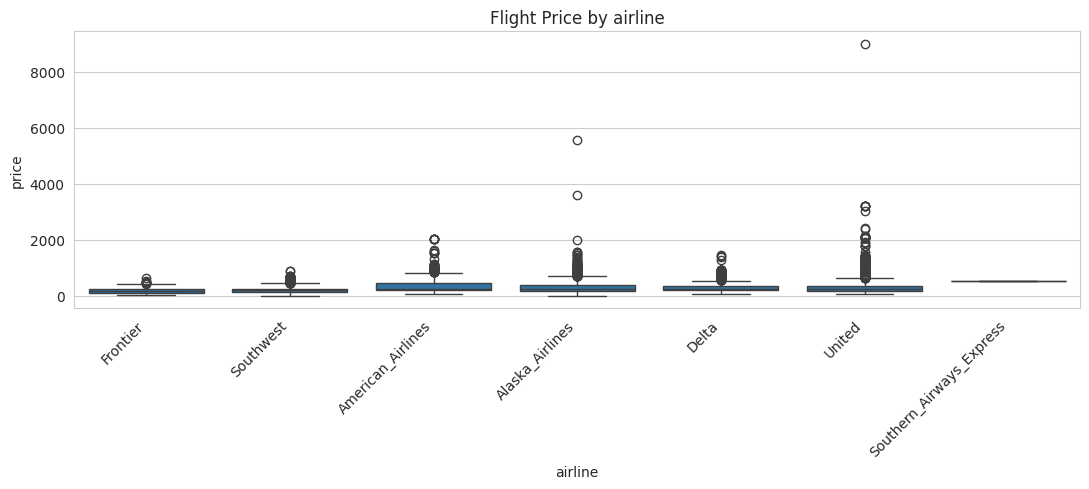

,count,mean,median
airline,,,
Southern_Airways_Express,1,543.000000,543.0
Delta,2972,286.528264,259.0
Alaska_Airlines,4554,302.619895,259.0
United,4058,319.028586,259.0
American_Airlines,1797,349.440178,253.0
Southwest,3895,197.837227,199.0
Frontier,799,178.583229,168.0


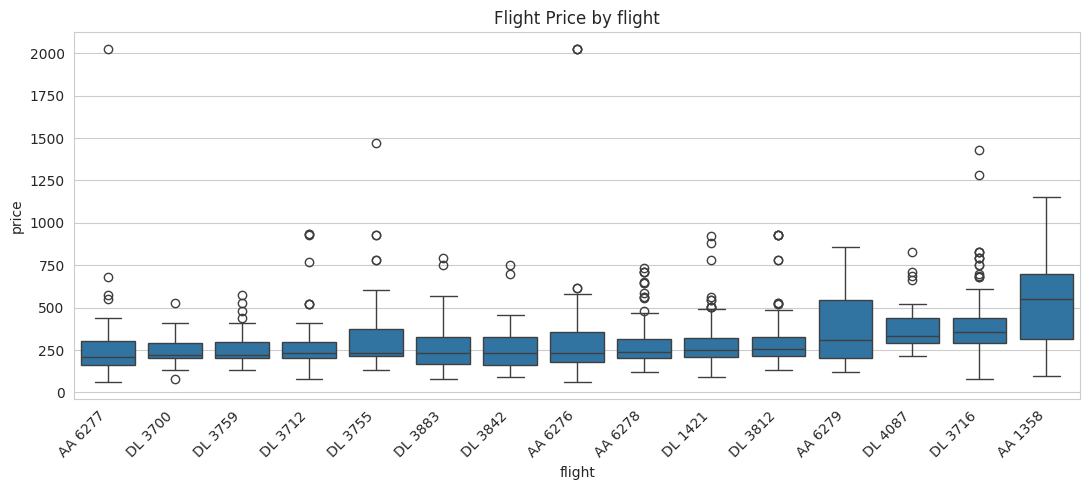

,count,mean,median
flight,,,
AS 2224,1,5564.000000,5564.0
UA 729,2,5160.500000,5160.5
UA 540,2,1607.500000,1607.5
AA 971,1,1597.000000,1597.0
AA 968,3,1514.000000,1514.0
UA 1961,17,1117.941176,1289.0
UA 1306,1,1278.000000,1278.0
AS 1355,4,1039.750000,1184.5
UA 2076,5,1131.800000,1131.0


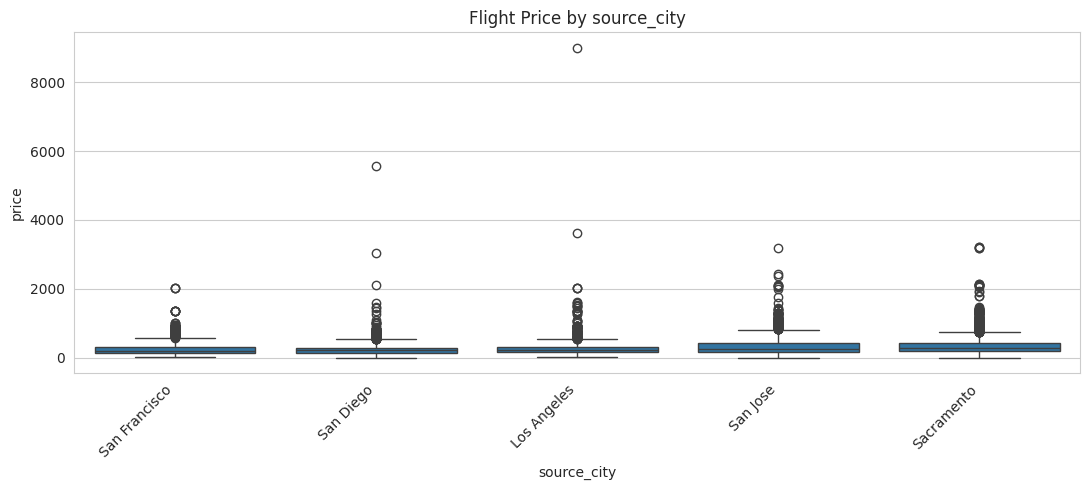

,count,mean,median
source_city,,,
Sacramento,3521,353.484521,279.0
San Jose,2217,341.190798,254.0
Los Angeles,4561,258.328437,224.0
San Diego,3691,234.069087,220.0
San Francisco,4086,250.327460,207.0


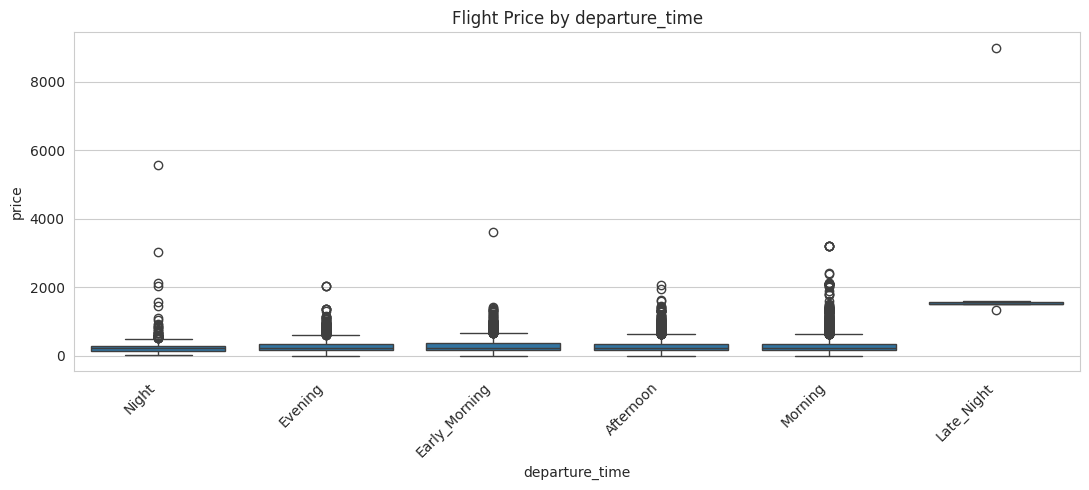

,count,mean,median
departure_time,,,
Late_Night,6,2743.333333,1514.0
Afternoon,3893,284.956589,234.0
Early_Morning,2820,294.459929,234.0
Morning,5144,298.018663,234.0
Evening,4436,260.789225,224.0
Night,1777,236.364660,217.0


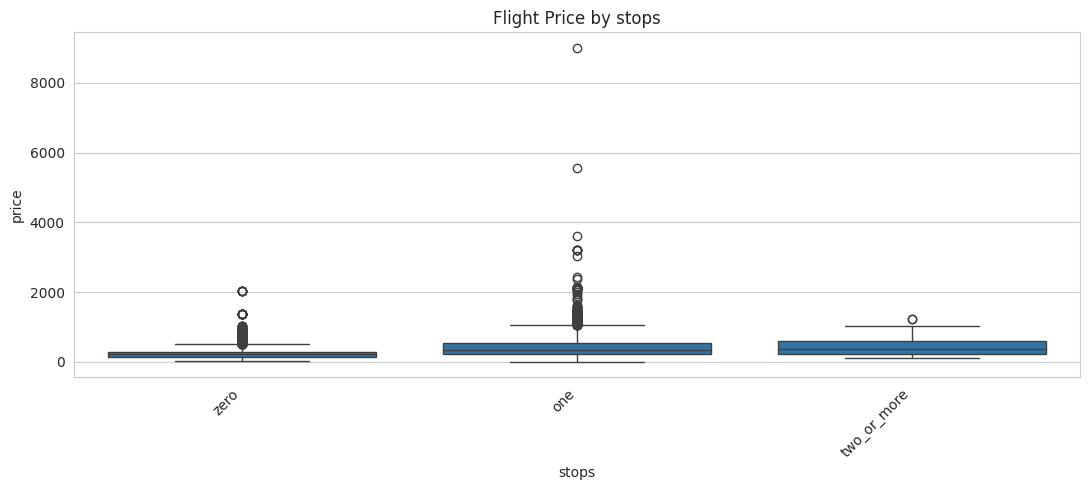

,count,mean,median
stops,,,
two_or_more,193,425.735751,370.0
one,4324,431.533996,347.0
zero,13559,229.953684,214.0


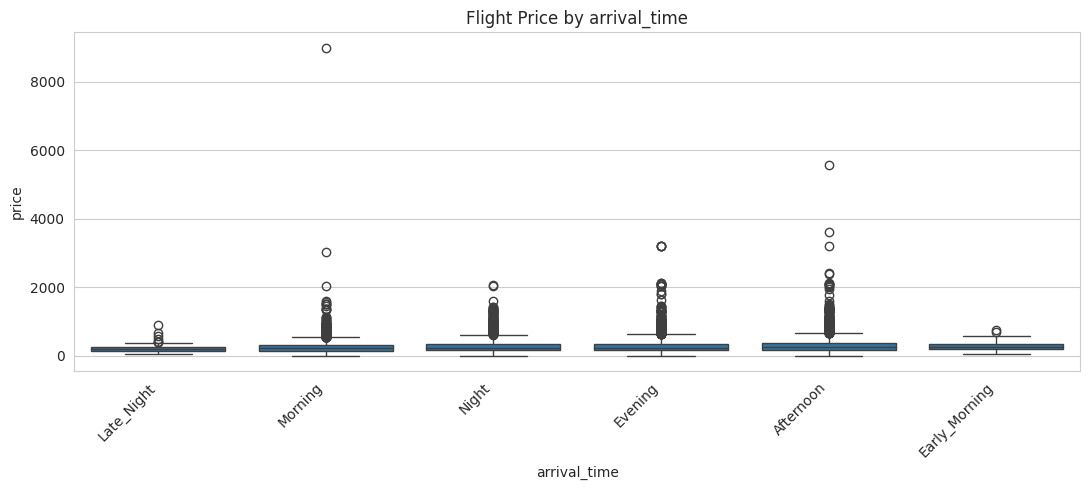

,count,mean,median
arrival_time,,,
Early_Morning,525,268.809524,259.0
Afternoon,4785,301.931870,242.0
Evening,4549,295.492196,234.0
Night,3701,274.236423,234.0
Morning,4364,249.593721,217.0
Late_Night,152,209.361842,199.0


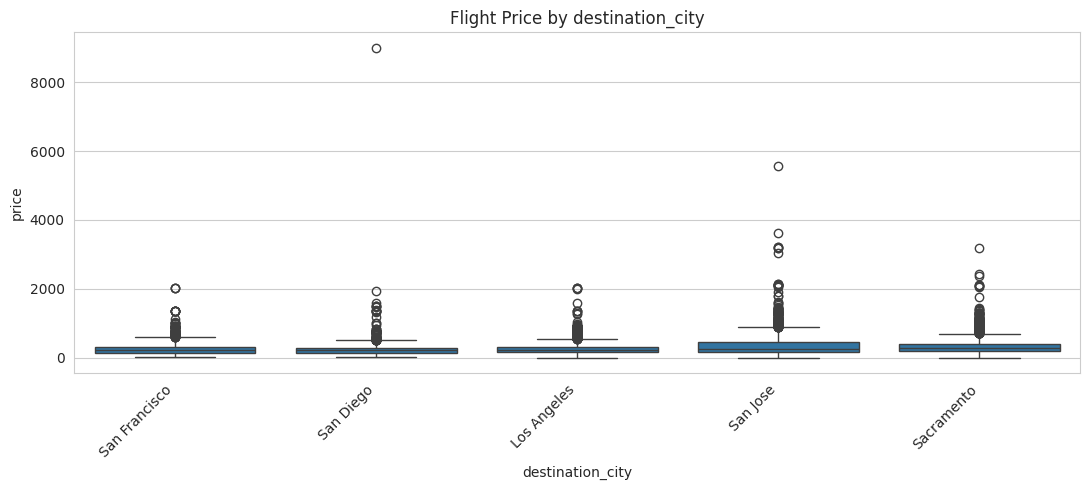

,count,mean,median
destination_city,,,
Sacramento,3303,337.820163,269.0
San Jose,2424,362.011964,264.0
Los Angeles,4533,258.688727,224.0
San Diego,3743,235.970077,219.0
San Francisco,4073,249.657010,215.0


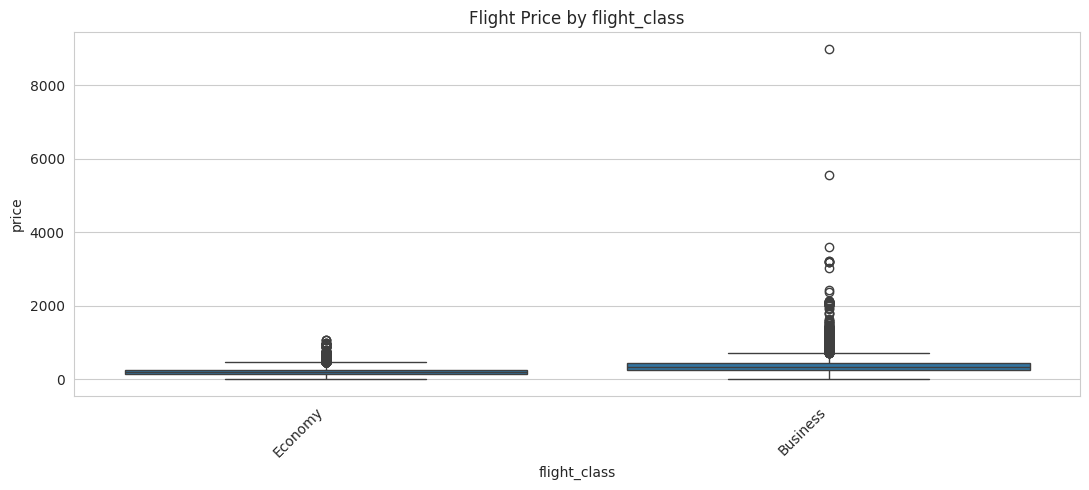

,count,mean,median
flight_class,,,
Business,7365,393.955465,323.0
Economy,10711,202.089441,194.0


In [11]:
# Plot categories with up to 20 distinct values. If a column has many categories,
# show the 15 categories with the most rows to keep the plots readable.
for col in categorical_cols:
    top_categories = train[col].value_counts(dropna=False).head(15).index
    plot_df = train[train[col].isin(top_categories)].copy()

    order = plot_df.groupby(col, dropna=False)["price"].median().sort_values().index
    plt.figure(figsize=(11, 5))
    sns.boxplot(data=plot_df, x=col, y="price", order=order)
    plt.title(f"Flight Price by {col}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    summary = train.groupby(col, dropna=False)["price"].agg(["count", "mean", "median"]).sort_values("median", ascending=False)
    display(summary.head(20))

These plots compare ticket prices across airlines, cities, departure/arrival time categories, number of stops, and flight class. Medians are often useful because very expensive tickets can pull means upward.

## 5. Relationships between categorical features

In [12]:
# Useful cross-tabs for understanding how categories are distributed.
for col in ["airline", "flight_class", "stops", "source_city", "destination_city"]:
    if col in train.columns:
        print(f"\nCounts for {col}")
        display(train[col].value_counts(dropna=False).to_frame("count"))


Counts for airline


,count
airline,
Alaska_Airlines,4554
United,4058
Southwest,3895
Delta,2972
American_Airlines,1797
Frontier,799
Southern_Airways_Express,1



Counts for flight_class


,count
flight_class,
Economy,10711
Business,7365



Counts for stops


,count
stops,
zero,13559
one,4324
two_or_more,193



Counts for source_city


,count
source_city,
Los Angeles,4561
San Francisco,4086
San Diego,3691
Sacramento,3521
San Jose,2217



Counts for destination_city


,count
destination_city,
Los Angeles,4533
San Francisco,4073
San Diego,3743
Sacramento,3303
San Jose,2424


## 6. Outlier audit using the IQR rule

In [13]:
def iqr_outlier_summary(series):
    s = series.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    count = ((s < low) | (s > high)).sum()
    return pd.Series({"lower_bound": low, "upper_bound": high, "outlier_count": count,
                      "outlier_pct": 100 * count / len(s) if len(s) else np.nan})

outlier_cols = [c for c in numeric_cols if c != "id"]
outlier_summary = pd.DataFrame({c: iqr_outlier_summary(train[c]) for c in outlier_cols}).T
display(outlier_summary.sort_values("outlier_pct", ascending=False))

,lower_bound,upper_bound,outlier_count,outlier_pct
duration,0.675,2.795,4516.0,24.983403
price,-111.500,604.500,1120.0,6.196061
days_left,-21.500,62.500,0.0,0.000000


In [14]:
Q1 = train["price"].quantile(0.25)
Q3 = train["price"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = train[
    (train["price"] < lower) |
    (train["price"] > upper)
]

print("Lower bound:", lower)
print("Upper bound:", upper)
print("Number of flagged prices:", len(outliers))

display(outliers.sort_values("price", ascending=False).head(10))

Lower bound: -111.5
Upper bound: 604.5
Number of flagged prices: 1120


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
15787,16,United,UA 729,Los Angeles,Late_Night,one,Morning,San Diego,Business,9.37,1,8996
15200,22275,Alaska_Airlines,AS 2224,San Diego,Night,one,Afternoon,San Jose,Business,14.52,43,5564
5936,19925,Alaska_Airlines,AS 668,Los Angeles,Early_Morning,one,Afternoon,San Jose,Business,5.58,37,3607
12601,11469,United,UA 1055,Sacramento,Morning,one,Evening,San Jose,Business,6.70,19,3204
2473,13008,United,UA 1055,Sacramento,Morning,one,Evening,San Jose,Business,6.70,23,3204
4249,7975,United,UA 1055,Sacramento,Morning,one,Evening,San Jose,Business,6.70,14,3194
10611,5522,United,UA 2013,San Jose,Morning,one,Afternoon,Sacramento,Business,6.28,10,3194
12674,5650,United,UA 1023,Sacramento,Morning,one,Evening,San Jose,Business,6.70,10,3194
7528,4233,United,UA 1100,San Diego,Night,one,Morning,San Jose,Business,13.27,9,3029
12109,19085,United,UA 2013,San Jose,Morning,one,Afternoon,Sacramento,Business,6.43,37,2424


This is giving outliers values. But is it genueine? So lets see how many business and economy among the outliers

In [15]:
# Compare price statistics by flight class
display(
    train.groupby("flight_class")["price"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

# Compare the number of IQR-flagged prices by class
Q1 = train["price"].quantile(0.25)
Q3 = train["price"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR

train["is_price_outlier"] = train["price"] > upper

display(
    train.groupby("flight_class")["is_price_outlier"]
    .agg(["sum", "mean"])
    .rename(columns={
        "sum": "outlier_count",
        "mean": "outlier_fraction"
    })
)

,count,mean,median,min,max
flight_class,,,,,
Business,7365,393.96,323.0,0,8996
Economy,10711,202.09,194.0,0,1071


,outlier_count,outlier_fraction
flight_class,,
Business,957,0.129939
Economy,163,0.015218


In [16]:
# Investigate zero-priced flights
zero_price = train[train["price"] <= 0]

print("Number of zero/negative-priced flights:", len(zero_price))
print("\nCount by flight class:")
display(zero_price["flight_class"].value_counts())

print("\nZero/negative-priced flight details:")
display(zero_price.head(20))

Number of zero/negative-priced flights: 25

Count by flight class:


,count
flight_class,
Economy,24
Business,1



Zero/negative-priced flight details:


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price,is_price_outlier
346,7703,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,13,0,False
934,12440,Southwest,WN 3903,Sacramento,Afternoon,one,Evening,San Jose,Economy,3.17,25,0,False
1352,13813,Southwest,WN 3797,San Jose,Morning,one,Afternoon,Sacramento,Economy,3.25,21,0,False
2762,4900,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,10,0,False
3101,5689,Southwest,WN 3687,Sacramento,Evening,one,Night,San Jose,Economy,3.08,9,0,False
4350,3307,Southwest,WN 2864,Sacramento,Morning,one,Morning,San Jose,Economy,3.08,6,0,False
5386,7879,Southwest,WN 3684,Sacramento,Morning,one,Afternoon,San Jose,Economy,3.08,15,0,False
5600,9839,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,16,0,False
5991,17620,Alaska_Airlines,AS 490,Sacramento,Early_Morning,one,Morning,San Jose,Economy,4.33,35,0,False
6642,4923,Southwest,WN 2864,Sacramento,Morning,one,Morning,San Jose,Economy,3.08,10,0,False


In [17]:
print("Negative prices:", (train["price"] < 0).sum())
print("Zero prices:", (train["price"] == 0).sum())
print("Positive prices:", (train["price"] > 0).sum())
print("Minimum price:", train["price"].min())

Negative prices: 0
Zero prices: 25
Positive prices: 18051
Minimum price: 0


It cannot have price value zero. So lets see more about the zero priced values

In [18]:
zero_price = train[train["price"] == 0]

display(zero_price)

print("\nZero-price count by class:")
display(zero_price["flight_class"].value_counts())

print("\nZero-price count by airline:")
display(zero_price["airline"].value_counts())

print("\nZero-price count by stops:")
display(zero_price["stops"].value_counts())

,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price,is_price_outlier
346,7703,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,13,0,False
934,12440,Southwest,WN 3903,Sacramento,Afternoon,one,Evening,San Jose,Economy,3.17,25,0,False
1352,13813,Southwest,WN 3797,San Jose,Morning,one,Afternoon,Sacramento,Economy,3.25,21,0,False
2762,4900,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,10,0,False
3101,5689,Southwest,WN 3687,Sacramento,Evening,one,Night,San Jose,Economy,3.08,9,0,False
4350,3307,Southwest,WN 2864,Sacramento,Morning,one,Morning,San Jose,Economy,3.08,6,0,False
5386,7879,Southwest,WN 3684,Sacramento,Morning,one,Afternoon,San Jose,Economy,3.08,15,0,False
5600,9839,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,16,0,False
5991,17620,Alaska_Airlines,AS 490,Sacramento,Early_Morning,one,Morning,San Jose,Economy,4.33,35,0,False
6642,4923,Southwest,WN 2864,Sacramento,Morning,one,Morning,San Jose,Economy,3.08,10,0,False



Zero-price count by class:


,count
flight_class,
Economy,24
Business,1



Zero-price count by airline:


,count
airline,
Southwest,23
Alaska_Airlines,2



Zero-price count by stops:


,count
stops,
one,25


These about the zero values

In [19]:
# Total flights and zero-priced flights by airline
airline_summary = train.groupby("airline").agg(
    total_flights=("price", "size"),
    zero_price_flights=("price", lambda s: (s == 0).sum())
)

airline_summary["zero_price_pct"] = (
    100 * airline_summary["zero_price_flights"]
    / airline_summary["total_flights"]
)

display(airline_summary.sort_values("zero_price_pct", ascending=False))

,total_flights,zero_price_flights,zero_price_pct
airline,,,
Southwest,3895,23,0.590501
Alaska_Airlines,4554,2,0.043917
American_Airlines,1797,0,0.000000
Delta,2972,0,0.000000
Frontier,799,0,0.000000
Southern_Airways_Express,1,0,0.000000
United,4058,0,0.000000


In [20]:
# Find flights with the same flight details but a positive price
features = [
    "airline", "flight", "source_city", "departure_time",
    "stops", "arrival_time", "destination_city",
    "flight_class", "duration", "days_left"
]

zero_rows = train[train["price"] == 0]

positive_rows = train[train["price"] > 0][features + ["price"]]

comparison = zero_rows[features].merge(
    positive_rows,
    on=features,
    how="left"
)

display(comparison.head(25))

print(
    "Zero-price rows with an exact feature match to a positive-price row:",
    comparison["price"].notna().sum()
)

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,13,NaN
1,Southwest,WN 3903,Sacramento,Afternoon,one,Evening,San Jose,Economy,3.17,25,NaN
2,Southwest,WN 3797,San Jose,Morning,one,Afternoon,Sacramento,Economy,3.25,21,NaN
3,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,10,NaN
4,Southwest,WN 3687,Sacramento,Evening,one,Night,San Jose,Economy,3.08,9,NaN
5,Southwest,WN 2864,Sacramento,Morning,one,Morning,San Jose,Economy,3.08,6,NaN
6,Southwest,WN 3684,Sacramento,Morning,one,Afternoon,San Jose,Economy,3.08,15,NaN
7,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,16,NaN
8,Alaska_Airlines,AS 490,Sacramento,Early_Morning,one,Morning,San Jose,Economy,4.33,35,NaN
9,Southwest,WN 2864,Sacramento,Morning,one,Morning,San Jose,Economy,3.08,10,NaN


Zero-price rows with an exact feature match to a positive-price row: 0


Analysis of price distribution and compare Economy vs Business class.

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

price_summary = train.groupby("flight_class")["price"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(price_summary.round(2))

,count,mean,median,std,min,max
flight_class,,,,,,
Business,7365,393.96,323.0,278.75,0,8996
Economy,10711,202.09,194.0,121.34,0,1071


The mean is higher than the median in both classes. This supports the right-skew pattern seen in your histogram.

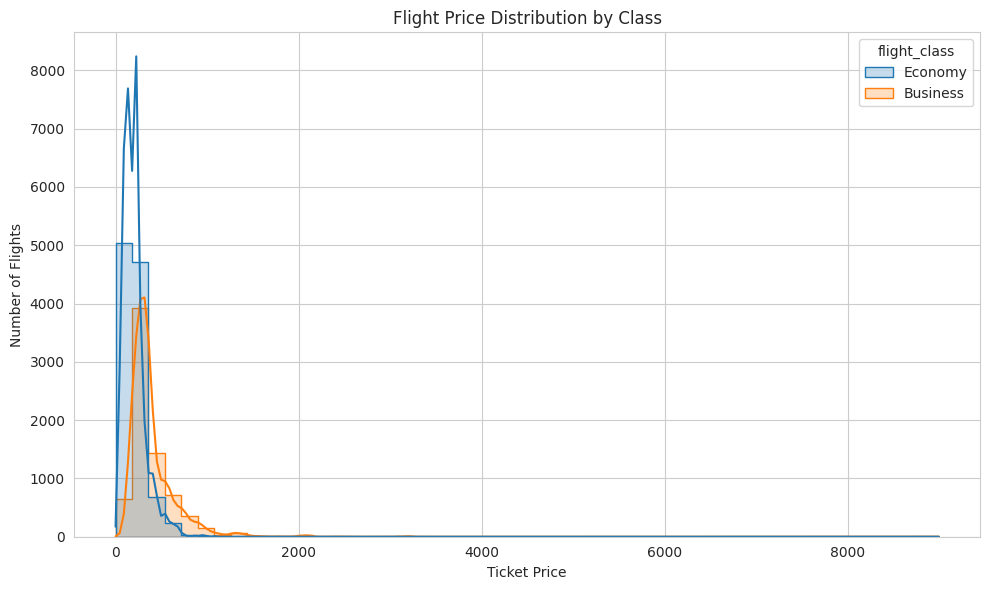

In [22]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=train,
    x="price",
    hue="flight_class",
    bins=50,
    kde=True,
    element="step"
)

plt.title("Flight Price Distribution by Class")
plt.xlabel("Ticket Price")
plt.ylabel("Number of Flights")
plt.tight_layout()
plt.show()

Both classes have right-skewed price distributions.
1. Most tickets are concentrated at lower prices.
2. A smaller number of tickets have much higher prices, creating the long right tail.
3. Business prices tend to extend further into the high-price range than Economy prices.

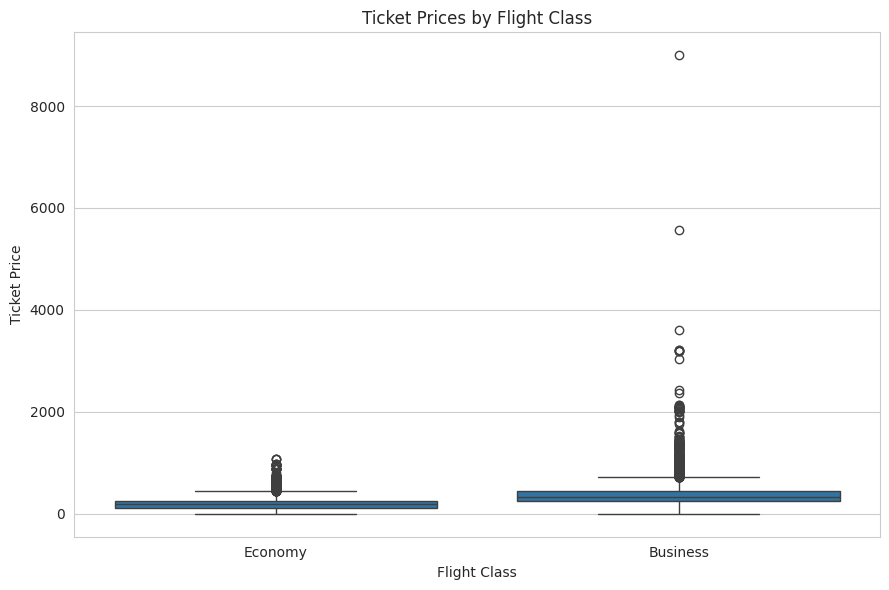

In [23]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=train,
    x="flight_class",
    y="price"
)

plt.title("Ticket Prices by Flight Class")
plt.xlabel("Flight Class")
plt.ylabel("Ticket Price")
plt.tight_layout()
plt.show()

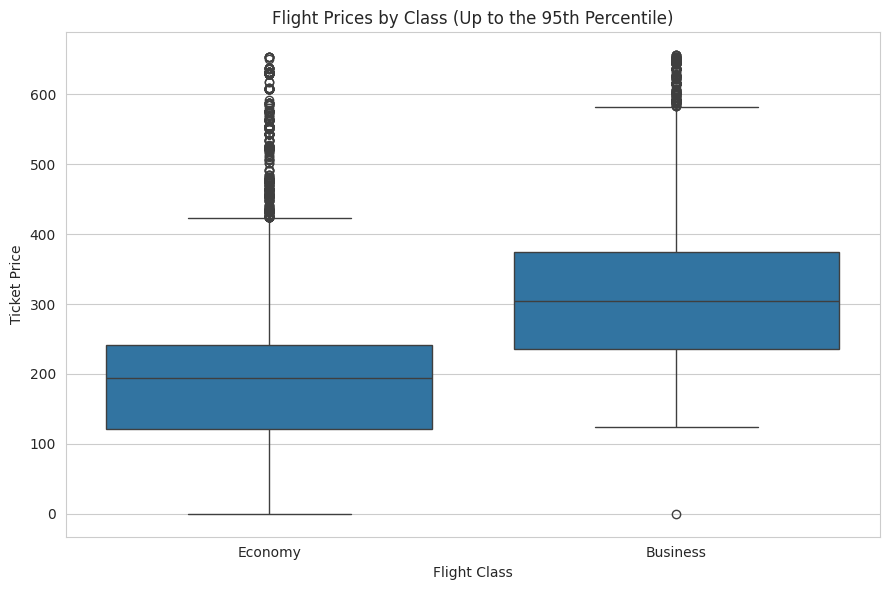

95th percentile price: 656.25


In [24]:
upper_limit = train["price"].quantile(0.95)

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=train[train["price"] <= upper_limit],
    x="flight_class",
    y="price"
)

plt.title("Flight Prices by Class (Up to the 95th Percentile)")
plt.xlabel("Flight Class")
plt.ylabel("Ticket Price")
plt.tight_layout()
plt.show()

print("95th percentile price:", upper_limit)

Compare price ranges

In [25]:
percentiles = (
    train.groupby("flight_class")["price"]
    .quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .unstack()
)

percentiles.columns = [
    "10%", "25%", "50% (Median)", "75%", "90%", "95%", "99%"
]

display(percentiles.round(2))

,10%,25%,50% (Median),75%,90%,95%,99%
flight_class,,,,,,,
Business,189.0,254.0,323.0,439.0,681.6,857.8,1364.0
Economy,69.0,123.0,194.0,254.0,336.0,434.0,632.0



Price statistics by airline:


,count,mean,median
airline,,,
Southern_Airways_Express,1,543.00,543.0
Delta,2972,286.53,259.0
Alaska_Airlines,4554,302.62,259.0
United,4058,319.03,259.0
American_Airlines,1797,349.44,253.0
Southwest,3895,197.84,199.0
Frontier,799,178.58,168.0


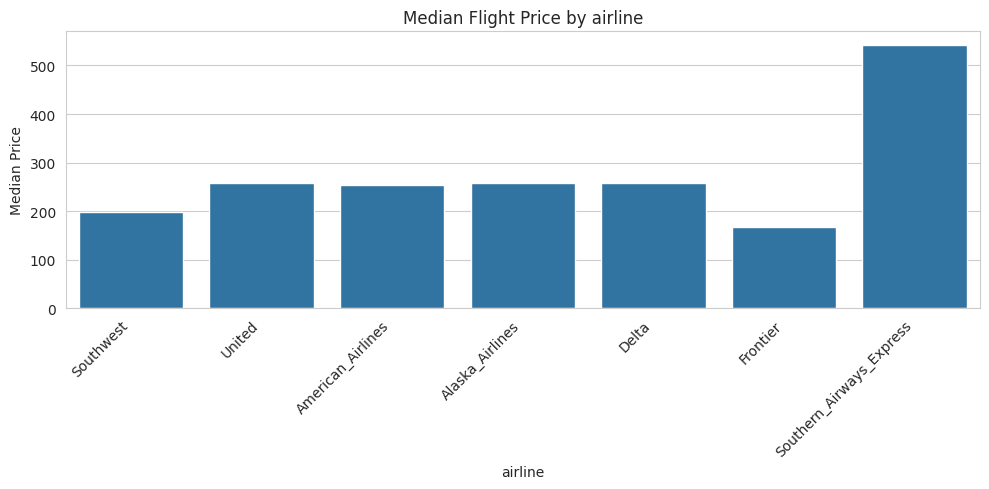


Price statistics by stops:


,count,mean,median
stops,,,
two_or_more,193,425.74,370.0
one,4324,431.53,347.0
zero,13559,229.95,214.0


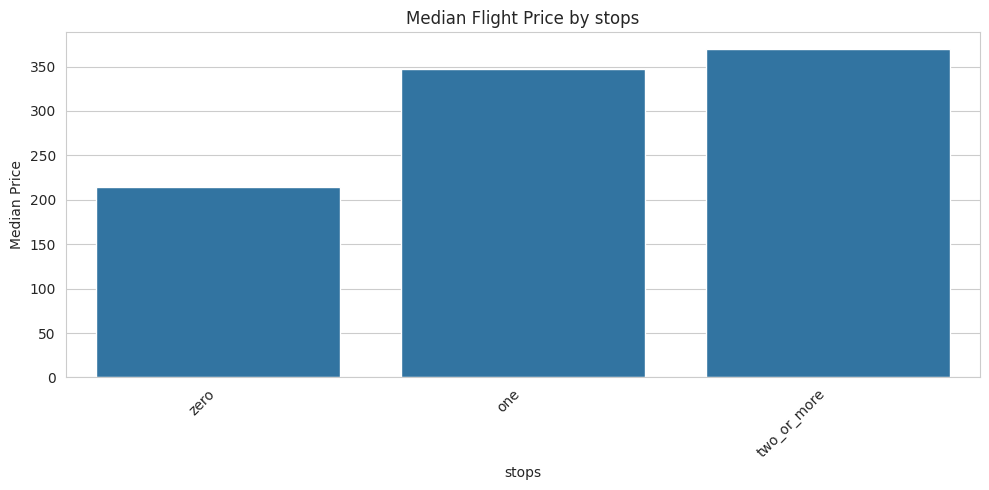


Price statistics by departure_time:


,count,mean,median
departure_time,,,
Late_Night,6,2743.33,1514.0
Afternoon,3893,284.96,234.0
Early_Morning,2820,294.46,234.0
Morning,5144,298.02,234.0
Evening,4436,260.79,224.0
Night,1777,236.36,217.0


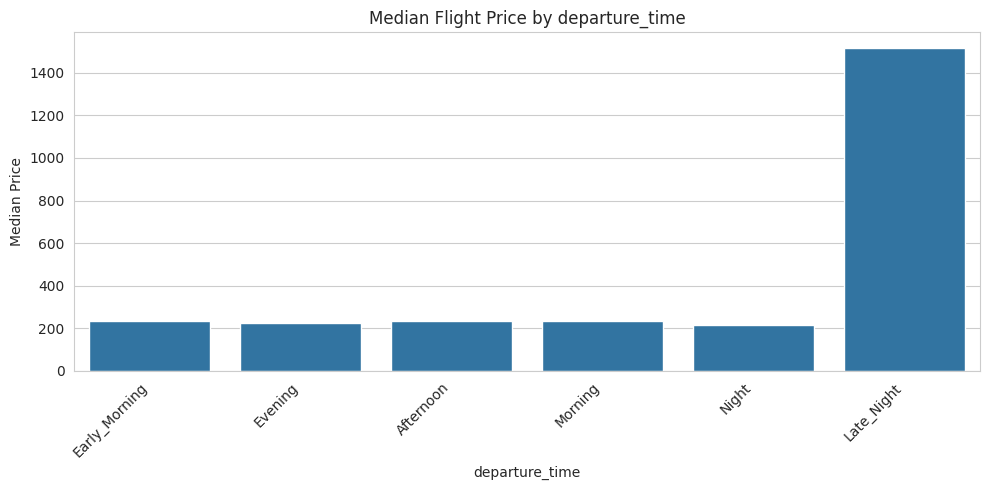


Price statistics by arrival_time:


,count,mean,median
arrival_time,,,
Early_Morning,525,268.81,259.0
Afternoon,4785,301.93,242.0
Evening,4549,295.49,234.0
Night,3701,274.24,234.0
Morning,4364,249.59,217.0
Late_Night,152,209.36,199.0


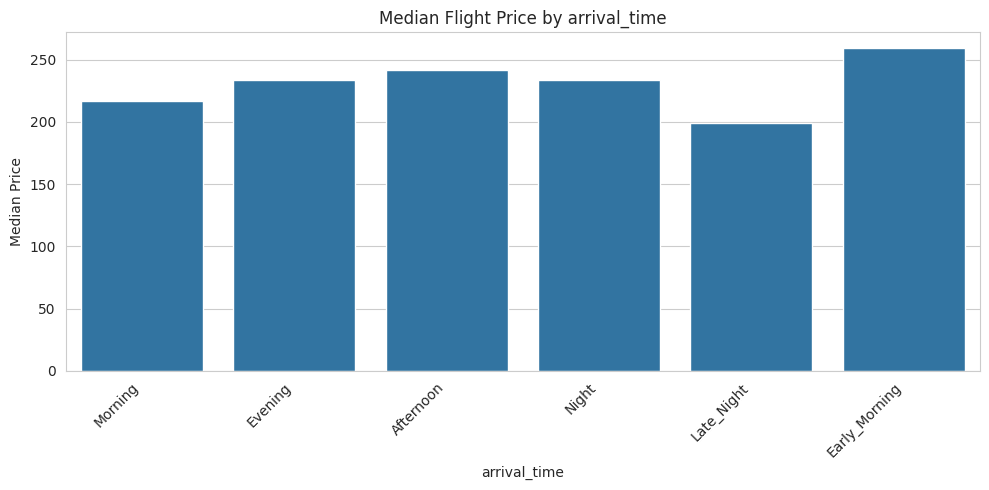


Price statistics by source_city:


,count,mean,median
source_city,,,
Sacramento,3521,353.48,279.0
San Jose,2217,341.19,254.0
Los Angeles,4561,258.33,224.0
San Diego,3691,234.07,220.0
San Francisco,4086,250.33,207.0


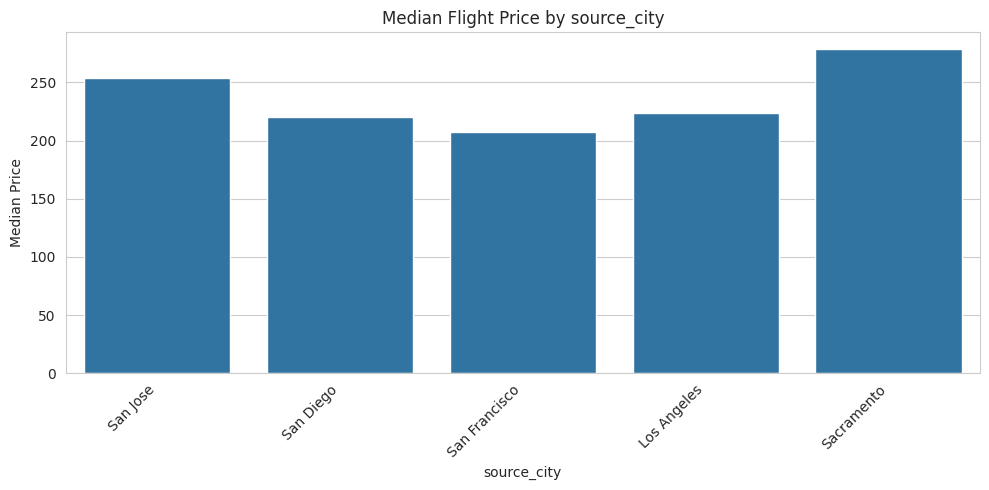


Price statistics by destination_city:


,count,mean,median
destination_city,,,
Sacramento,3303,337.82,269.0
San Jose,2424,362.01,264.0
Los Angeles,4533,258.69,224.0
San Diego,3743,235.97,219.0
San Francisco,4073,249.66,215.0


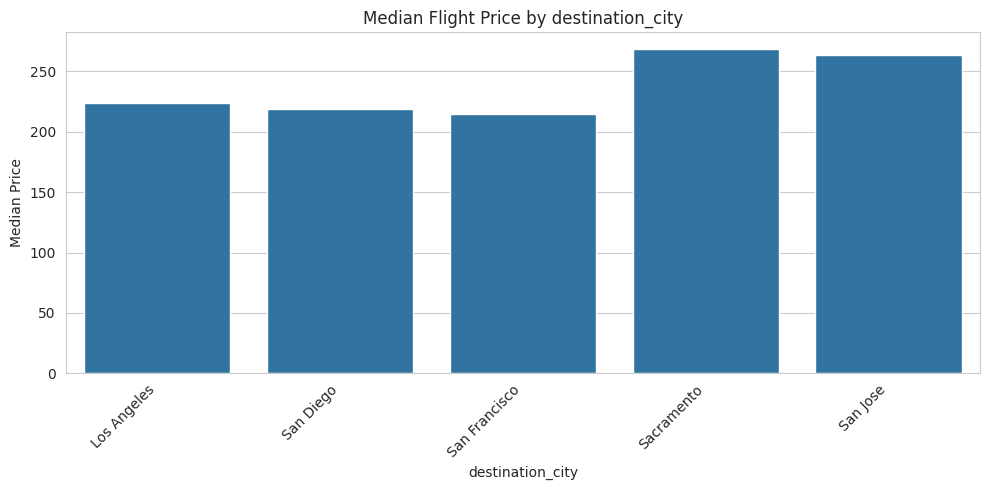


Price statistics by flight_class:


,count,mean,median
flight_class,,,
Business,7365,393.96,323.0
Economy,10711,202.09,194.0


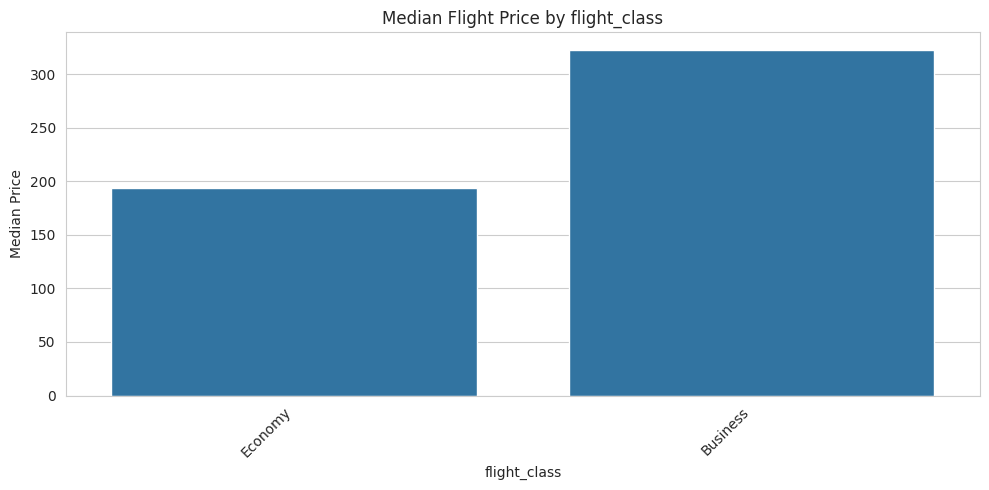

In [26]:
# Compare median price across important categorical features
categorical_features = [
    "airline",
    "stops",
    "departure_time",
    "arrival_time",
    "source_city",
    "destination_city",
    "flight_class"
]

for col in categorical_features:
    summary = (
        train.groupby(col, dropna=False)["price"]
        .agg(["count", "mean", "median"])
        .sort_values("median", ascending=False)
    )

    print(f"\nPrice statistics by {col}:")
    display(summary.round(2))

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=train,
        x=col,
        y="price",
        estimator="median",
        errorbar=None
    )
    plt.title(f"Median Flight Price by {col}")
    plt.xlabel(col)
    plt.ylabel("Median Price")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

Linear regression among the dataset seperately for business and economy class

In [29]:

import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from google.colab import files

# IMPORTANT: Include flight this time; exclude only target and id
X = train.drop(columns=["price", "id"]).copy()
y = train["price"].copy()

X_test = test.drop(columns=["id"]).copy()

predictions = np.zeros(len(test))
flight_models = {}

for cls in ["Economy", "Business"]:
    train_mask = X["flight_class"] == cls
    test_mask = X_test["flight_class"] == cls

    X_train_cls = X.loc[train_mask].drop(
        columns=["flight_class"]
    )
    y_train_cls = y.loc[train_mask]

    X_test_cls = X_test.loc[test_mask].drop(
        columns=["flight_class"]
    ).copy()

    # Treat flight as a categorical feature
    cat_cols = X_train_cls.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    num_cols = X_train_cls.select_dtypes(
        include=np.number
    ).columns.tolist()

    preprocess = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore"
            ))
        ]), cat_cols)
    ])

    model = Pipeline([
        ("preprocess", preprocess),
        ("regressor", ExtraTreesRegressor(
            n_estimators=400,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=2,
            max_features=0.9,
            random_state=42,
            n_jobs=-1
        ))
    ])

    print(f"Training Extra Trees for {cls}...")
    model.fit(X_train_cls, y_train_cls)

    predictions[np.where(test_mask)[0]] = model.predict(
        X_test_cls
    )

    flight_models[cls] = model
    print(f"{cls} finished!")

# Build submission in the original test-row order
submission = sample_submission.copy()
submission["id"] = test["id"].values
submission["price"] = predictions

assert len(submission) == len(test)
assert submission["price"].notna().all()
assert submission.columns.tolist() == ["id", "price"]

filename = "extra_trees_with_flight_submission.csv"
submission.to_csv(filename, index=False)

print("Submission created:", filename)
print("Rows:", len(submission))
display(submission.head())

files.download(filename)


Training Extra Trees for Economy...
Economy finished!
Training Extra Trees for Business...
Business finished!
Submission created: extra_trees_with_flight_submission.csv
Rows: 4520


,id,price
0,18395,59.260417
1,11771,158.337917
2,22326,359.219792
3,18332,142.233125
4,11021,554.574172


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [30]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import files

# ==========================================
# 1. Prepare data, INCLUDING flight
# ==========================================
X = train.drop(columns=["price", "id"]).copy()
y = train["price"].copy()

# Same 80/20 split used in earlier experiments
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

validation_models = {}
results = []

# ==========================================
# 2. Train and evaluate each class
# ==========================================
for cls in ["Economy", "Business"]:

    train_mask = X_train["flight_class"] == cls
    val_mask = X_val["flight_class"] == cls

    A = X_train.loc[train_mask].drop(
        columns=["flight_class"]
    )
    B = X_val.loc[val_mask].drop(
        columns=["flight_class"]
    )

    ya = y_train.loc[train_mask]
    yv = y_val.loc[val_mask]

    cat_cols = A.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
    num_cols = A.select_dtypes(
        include=np.number
    ).columns.tolist()

    preprocess = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols)
    ])

    model = Pipeline([
        ("preprocess", preprocess),
        ("regressor", ExtraTreesRegressor(
            n_estimators=400,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=2,
            max_features=0.9,
            random_state=42,
            n_jobs=-1
        ))
    ])

    print(f"Training validation model: {cls}")
    model.fit(A, ya)
    pred = model.predict(B)

    # Regression metrics
    mae = mean_absolute_error(yv, pred)
    rmse = np.sqrt(mean_squared_error(yv, pred))
    r2 = r2_score(yv, pred)

    # Tolerance-based accuracy-like metrics
    nonzero = yv.to_numpy() != 0
    actual = yv.to_numpy()[nonzero]
    predicted = pred[nonzero]

    relative_error = (
        np.abs(predicted - actual) / np.abs(actual)
    )

    within_10 = np.mean(relative_error <= 0.10) * 100
    within_20 = np.mean(relative_error <= 0.20) * 100

    results.append({
        "Class": cls,
        "Validation Rows": len(yv),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Within 10% (%)": within_10,
        "Within 20% (%)": within_20
    })

    validation_models[cls] = model

# Show validation results
results_df = pd.DataFrame(results)
display(results_df.round(3))

# ==========================================
# 3. Train final models on ALL training data
# ==========================================
final_models = {}

for cls in ["Economy", "Business"]:
    mask = X["flight_class"] == cls

    A = X.loc[mask].drop(columns=["flight_class"])
    ya = y.loc[mask]

    model = validation_models[cls]
    model.fit(A, ya)

    final_models[cls] = model
    print(f"Final model trained: {cls}")

# ==========================================
# 4. Predict test data and download submission
# ==========================================
X_test = test.drop(columns=["id"]).copy()
test_predictions = np.zeros(len(test))

for cls in ["Economy", "Business"]:
    mask = X_test["flight_class"] == cls

    B = X_test.loc[mask].drop(columns=["flight_class"])

    test_predictions[np.where(mask)[0]] = (
        final_models[cls].predict(B)
    )

submission = sample_submission.copy()
submission["id"] = test["id"].values
submission["price"] = test_predictions

assert len(submission) == len(test)
assert submission["price"].notna().all()

filename = "extra_trees_with_flight_validated.csv"
submission.to_csv(filename, index=False)

print("Submission ready:", filename)
display(submission.head())

files.download(filename)


Training validation model: Economy
Training validation model: Business


,Class,Validation Rows,MAE,RMSE,R2,Within 10% (%),Within 20% (%)
0,Economy,2130,18.396,43.345,0.878,70.217,83.977
1,Business,1486,84.820,218.830,0.480,46.770,64.468


Final model trained: Economy
Final model trained: Business
Submission ready: extra_trees_with_flight_validated.csv


,id,price
0,18395,59.260417
1,11771,158.337917
2,22326,359.219792
3,18332,142.233125
4,11021,554.574172


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Separate features and target
# Exclude ID and flight number for this baseline.
X = train.drop(columns=["price", "id", "flight"])
y = train["price"]

# 2. Split BEFORE training to avoid validation leakage
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

results = []
models = {}

# 3. Train one model per flight class
for flight_class in ["Economy", "Business"]:

    # Select rows belonging to this class
    train_mask = X_train["flight_class"] == flight_class
    val_mask = X_val["flight_class"] == flight_class

    # Remove flight_class because it is constant within each subset
    X_tr = X_train.loc[train_mask].drop(columns=["flight_class"])
    X_v = X_val.loc[val_mask].drop(columns=["flight_class"])

    y_tr = y_train.loc[train_mask]
    y_v = y_val.loc[val_mask]

    # Identify categorical and numerical columns
    cat_cols = X_tr.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    num_cols = X_tr.select_dtypes(
        include=np.number
    ).columns.tolist()

    # Preprocessing
    preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_cols),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols)
    ])

    # Complete pipeline
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])

    # Train
    model.fit(X_tr, y_tr)

    # Predict on validation rows
    predictions = model.predict(X_v)

    # Evaluate
    mae = mean_absolute_error(y_v, predictions)
    rmse = np.sqrt(mean_squared_error(y_v, predictions))
    r2 = r2_score(y_v, predictions)

    models[flight_class] = model

    results.append({
        "Flight Class": flight_class,
        "Training Rows": len(X_tr),
        "Validation Rows": len(X_v),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Flight Class,Training Rows,Validation Rows,MAE,RMSE,R2
0,Economy,8581,2130,58.893,84.502,0.538
1,Business,5879,1486,130.787,257.100,0.283


In [28]:
# 1. Prepare test features
X_test = test.drop(columns=["id", "flight"], errors="ignore")

# 2. Create an array to store predictions in the original test-row order
test_predictions = np.zeros(len(test))

# 3. Predict separately for each flight class
for flight_class in ["Economy", "Business"]:

    mask = X_test["flight_class"] == flight_class

    # The models were trained without flight_class
    X_class = X_test.loc[mask].drop(columns=["flight_class"])

    # Predict using the matching model
    test_predictions[np.where(mask)[0]] = models[flight_class].predict(X_class)

# 4. Create submission
submission = sample_submission.copy()
submission["id"] = test["id"].values
submission["price"] = test_predictions

# 5. Validate submission
assert len(submission) == len(test)
assert submission.columns.tolist() == ["id", "price"]
assert submission["price"].notna().all()

display(submission.head())
print("Submission shape:", submission.shape)
print("Missing predictions:", submission["price"].isna().sum())
print("Minimum predicted price:", submission["price"].min())
print("Maximum predicted price:", submission["price"].max())

# 6. Save file
submission.to_csv("linear_regression_class_submission.csv", index=False)

from google.colab import files
files.download("linear_regression_class_submission.csv")

,id,price
0,18395,72.364479
1,11771,173.581342
2,22326,598.088476
3,18332,148.776465
4,11021,347.407068


Submission shape: (4520, 2)
Missing predictions: 0
Minimum predicted price: -47.50592800855293
Maximum predicted price: 2768.6804423222156


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Random forest based on class

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare features and target
X = train.drop(columns=["price", "id", "flight"])
y = train["price"]

# Same validation split as the Linear Regression experiment
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

results = []
rf_models = {}

for flight_class in ["Economy", "Business"]:

    # Select rows of the current class
    train_mask = X_train["flight_class"] == flight_class
    val_mask = X_val["flight_class"] == flight_class

    X_tr = X_train.loc[train_mask].drop(columns=["flight_class"])
    X_v = X_val.loc[val_mask].drop(columns=["flight_class"])

    y_tr = y_train.loc[train_mask]
    y_v = y_val.loc[val_mask]

    # Identify column types from training data only
    cat_cols = X_tr.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    num_cols = X_tr.select_dtypes(
        include=np.number
    ).columns.tolist()

    # Preprocessing
    preprocessor = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols)
    ])

    # Random Forest pipeline
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Train
    model.fit(X_tr, y_tr)

    # Validate
    predictions = model.predict(X_v)

    mae = mean_absolute_error(y_v, predictions)
    rmse = np.sqrt(mean_squared_error(y_v, predictions))
    r2 = r2_score(y_v, predictions)

    # Optional tolerance-based accuracy-like metrics
    nonzero = y_v != 0
    relative_error = (
        np.abs(predictions[nonzero] - y_v[nonzero])
        / np.abs(y_v[nonzero])
    )

    rf_models[flight_class] = model

    results.append({
        "Flight Class": flight_class,
        "Training Rows": len(X_tr),
        "Validation Rows": len(X_v),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Within 10% (%)": (relative_error <= 0.10).mean() * 100,
        "Within 20% (%)": (relative_error <= 0.20).mean() * 100
    })

rf_results = pd.DataFrame(results)
display(rf_results.round(3))

,Flight Class,Training Rows,Validation Rows,MAE,RMSE,R2,Within 10% (%),Within 20% (%)
0,Economy,8581,2130,18.566,40.330,0.895,69.557,82.941
1,Business,5879,1486,87.220,223.424,0.458,43.136,64.401


In [ ]:
# Prepare test features
X_test = test.drop(columns=["id", "flight"], errors="ignore")

# Store predictions in original test-row order
test_predictions = np.zeros(len(test))

for flight_class in ["Economy", "Business"]:

    mask = X_test["flight_class"] == flight_class

    X_class = X_test.loc[mask].drop(columns=["flight_class"])

    test_predictions[np.where(mask)[0]] = (
        rf_models[flight_class].predict(X_class)
    )

# Create Kaggle submission
submission = sample_submission.copy()
submission["id"] = test["id"].values
submission["price"] = test_predictions

# Verify
assert len(submission) == len(test)
assert submission["price"].notna().all()
assert submission.columns.tolist() == ["id", "price"]

display(submission.head())

print("Submission shape:", submission.shape)
print("Minimum predicted price:", submission["price"].min())
print("Maximum predicted price:", submission["price"].max())

submission.to_csv(
    "random_forest_class_submission.csv",
    index=False
)

from google.colab import files
files.download("random_forest_class_submission.csv")

,id,price
0,18395,62.552143
1,11771,159.000000
2,22326,379.001679
3,18332,137.385625
4,11021,550.678587


Submission shape: (4520, 2)
Minimum predicted price: 22.06908730158731
Maximum predicted price: 2697.60978835979


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tune random forest seperately

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

rf_tuned_models = {}
tuning_results = []

param_grid = {
    "regressor__n_estimators": [300, 500],
    "regressor__max_features": [0.7, 1.0],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_depth": [None, 20, 30]
}

for flight_class in ["Economy", "Business"]:

    train_mask = X_train["flight_class"] == flight_class
    val_mask = X_val["flight_class"] == flight_class

    X_tr = X_train.loc[train_mask].drop(columns=["flight_class"])
    X_v = X_val.loc[val_mask].drop(columns=["flight_class"])
    y_tr = y_train.loc[train_mask]
    y_v = y_val.loc[val_mask]

    cat_cols = X_tr.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    num_cols = X_tr.select_dtypes(
        include=np.number
    ).columns.tolist()

    preprocessor = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols)
    ])

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ))
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grid,
        n_iter=12,
        scoring="neg_root_mean_squared_error",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_tr, y_tr)

    best_model = search.best_estimator_
    predictions = best_model.predict(X_v)

    rf_tuned_models[flight_class] = best_model

    tuning_results.append({
        "Class": flight_class,
        "Best CV RMSE": -search.best_score_,
        "Validation MAE": mean_absolute_error(y_v, predictions),
        "Validation RMSE": np.sqrt(
            mean_squared_error(y_v, predictions)
        ),
        "Validation R2": r2_score(y_v, predictions),
        "Best Parameters": search.best_params_
    })

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Fitting 3 folds for each of 12 candidates, totalling 36 fits


,Class,Best CV RMSE,Validation MAE,Validation RMSE,Validation R2,Best Parameters
0,Economy,41.977953,18.046542,39.992930,0.896486,"{'regressor__n_estimators': 500, 'regressor__m..."
1,Business,175.351605,87.276323,224.227871,0.454261,"{'regressor__n_estimators': 300, 'regressor__m..."


In [ ]:
test_predictions = np.zeros(len(test))

X_test = test.drop(
    columns=["id", "flight"], errors="ignore"
)

for flight_class in ["Economy", "Business"]:
    mask = X_test["flight_class"] == flight_class

    X_class = X_test.loc[mask].drop(
        columns=["flight_class"]
    )

    test_predictions[np.where(mask)[0]] = (
        rf_tuned_models[flight_class].predict(X_class)
    )

submission = sample_submission.copy()
submission["id"] = test["id"].values
submission["price"] = test_predictions

assert submission["price"].notna().all()
assert len(submission) == len(test)

submission.to_csv(
    "tuned_random_forest_class_submission.csv",
    index=False
)

from google.colab import files
files.download("tuned_random_forest_class_submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Seperate-class extra trees

In [ ]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

et_models = {}
et_results = []

param_grid = {
    "regressor__n_estimators": [300, 500, 700],
    "regressor__max_depth": [None, 20, 30, 40],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": [0.7, 1.0]
}

for flight_class in ["Economy", "Business"]:

    train_mask = X_train["flight_class"] == flight_class
    val_mask = X_val["flight_class"] == flight_class

    X_tr = X_train.loc[train_mask].drop(columns=["flight_class"])
    X_v = X_val.loc[val_mask].drop(columns=["flight_class"])
    y_tr = y_train.loc[train_mask]
    y_v = y_val.loc[val_mask]

    cat_cols = X_tr.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    num_cols = X_tr.select_dtypes(
        include=np.number
    ).columns.tolist()

    preprocessor = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols)
    ])

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", ExtraTreesRegressor(
            random_state=42,
            n_jobs=1
        ))
    ])

    search = RandomizedSearchCV(
        pipeline,
        param_distributions=param_grid,
        n_iter=15,
        scoring="neg_root_mean_squared_error",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_tr, y_tr)

    best_model = search.best_estimator_
    predictions = best_model.predict(X_v)

    et_models[flight_class] = best_model

    et_results.append({
        "Class": flight_class,
        "Best CV RMSE": -search.best_score_,
        "Validation MAE": mean_absolute_error(y_v, predictions),
        "Validation RMSE": np.sqrt(
            mean_squared_error(y_v, predictions)
        ),
        "Validation R2": r2_score(y_v, predictions),
        "Best Parameters": search.best_params_
    })

et_results_df = pd.DataFrame(et_results)
display(et_results_df)


Fitting 3 folds for each of 15 candidates, totalling 45 fits
Fitting 3 folds for each of 15 candidates, totalling 45 fits


,Class,Best CV RMSE,Validation MAE,Validation RMSE,Validation R2,Best Parameters
0,Economy,42.673628,19.421313,41.06858,0.890843,"{'regressor__n_estimators': 300, 'regressor__m..."
1,Business,179.265956,86.256768,217.68206,0.485659,"{'regressor__n_estimators': 300, 'regressor__m..."


In [ ]:

from sklearn.base import clone

final_et_models = {}

for flight_class in ["Economy", "Business"]:

    mask = X["flight_class"] == flight_class

    X_class = X.loc[mask].drop(columns=["flight_class"])
    y_class = y.loc[mask]

    final_model = clone(et_models[flight_class])
    final_model.fit(X_class, y_class)

    final_et_models[flight_class] = final_model

print("Both Extra Trees models trained on all training data.")


Both Extra Trees models trained on all training data.


In [ ]:

X_test = test.drop(columns=["id", "flight"], errors="ignore")
test_predictions = np.zeros(len(test))

for flight_class in ["Economy", "Business"]:

    mask = X_test["flight_class"] == flight_class
    X_class = X_test.loc[mask].drop(columns=["flight_class"])

    test_predictions[np.where(mask)[0]] = (
        final_et_models[flight_class].predict(X_class)
    )

submission = sample_submission.copy()
submission["id"] = test["id"].values
submission["price"] = test_predictions

assert len(submission) == len(test)
assert submission["price"].notna().all()

submission.to_csv(
    "separate_class_extra_trees.csv",
    index=False
)

from google.colab import files
files.download("separate_class_extra_trees.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Adding route feature

In [ ]:
print(
    et_results_df[["Class", "Best Parameters"]]
    .to_string(index=False)
)

   Class                                                                                                                                                     Best Parameters
 Economy   {'regressor__n_estimators': 300, 'regressor__min_samples_split': 5, 'regressor__min_samples_leaf': 1, 'regressor__max_features': 0.7, 'regressor__max_depth': 30}
Business {'regressor__n_estimators': 300, 'regressor__min_samples_split': 2, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 0.7, 'regressor__max_depth': None}


In [ ]:

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Start from the original training data
X_route = train.drop(columns=["price", "id", "flight"]).copy()
y_route = train["price"].copy()

# Create a directional route feature
X_route["route"] = (
    X_route["source_city"].astype(str)
    + "_to_"
    + X_route["destination_city"].astype(str)
)

Xtr, Xval, ytr, yval = train_test_split(
    X_route, y_route, test_size=0.2, random_state=42
)

route_models = {}
route_results = []

param_grid = {
    "regressor__n_estimators": [300, 500, 700],
    "regressor__max_depth": [None, 20, 30, 40],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": [0.7, 1.0]
}

for cls in ["Economy", "Business"]:
    mtr = Xtr["flight_class"] == cls
    mval = Xval["flight_class"] == cls

    A = Xtr.loc[mtr].drop(columns=["flight_class"])
    B = Xval.loc[mval].drop(columns=["flight_class"])
    ya = ytr.loc[mtr]
    yb = yval.loc[mval]

    cats = A.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
    nums = A.select_dtypes(include=np.number).columns.tolist()

    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), nums),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), cats)
    ])

    pipe = Pipeline([
        ("preprocessor", prep),
        ("regressor", ExtraTreesRegressor(
            random_state=42, n_jobs=1
        ))
    ])

    search = RandomizedSearchCV(
        pipe,
        param_distributions=param_grid,
        n_iter=12,
        scoring="neg_root_mean_squared_error",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    search.fit(A, ya)
    pred = search.predict(B)

    route_models[cls] = search.best_estimator_

    route_results.append({
        "Class": cls,
        "CV RMSE": -search.best_score_,
        "Validation MAE": mean_absolute_error(yb, pred),
        "Validation RMSE": np.sqrt(mean_squared_error(yb, pred)),
        "Validation R2": r2_score(yb, pred),
        "Best Parameters": search.best_params_
    })

route_results_df = pd.DataFrame(route_results)
display(route_results_df)


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Fitting 3 folds for each of 12 candidates, totalling 36 fits


,Class,CV RMSE,Validation MAE,Validation RMSE,Validation R2,Best Parameters
0,Economy,41.669135,18.343579,40.412853,0.894301,"{'regressor__n_estimators': 300, 'regressor__m..."
1,Business,179.015671,85.862717,215.261111,0.497036,"{'regressor__n_estimators': 300, 'regressor__m..."


In [ ]:

import numpy as np
import pandas as pd
from sklearn.base import clone
from google.colab import files

# Prepare all training features
X_route = train.drop(columns=["price", "id", "flight"]).copy()
y_route = train["price"].copy()

X_route["route"] = (
    X_route["source_city"].astype(str)
    + "_to_"
    + X_route["destination_city"].astype(str)
)

# Prepare test features using the same route engineering
X_test_route = test.drop(columns=["id", "flight"]).copy()

X_test_route["route"] = (
    X_test_route["source_city"].astype(str)
    + "_to_"
    + X_test_route["destination_city"].astype(str)
)

# Train each selected model on all available rows of its class
final_route_models = {}

for cls in ["Economy", "Business"]:
    train_mask = X_route["flight_class"] == cls
    test_mask = X_test_route["flight_class"] == cls

    X_class = X_route.loc[train_mask].drop(
        columns=["flight_class"]
    )
    y_class = y_route.loc[train_mask]

    model = clone(route_models[cls])
    model.fit(X_class, y_class)
    final_route_models[cls] = model

# Predict while preserving original test-row order
test_predictions = np.zeros(len(test))

for cls in ["Economy", "Business"]:
    mask = X_test_route["flight_class"] == cls

    X_class_test = X_test_route.loc[mask].drop(
        columns=["flight_class"]
    )

    test_predictions[np.where(mask)[0]] = (
        final_route_models[cls].predict(X_class_test)
    )

# Create submission
submission = sample_submission.copy()
submission["id"] = test["id"].values
submission["price"] = test_predictions

assert len(submission) == len(test)
assert submission["price"].notna().all()
assert submission.columns.tolist() == ["id", "price"]

filename = "extra_trees_route_submission.csv"
submission.to_csv(filename, index=False)

print("Submission shape:", submission.shape)
display(submission.head())

files.download(filename)


Submission shape: (4520, 2)


,id,price
0,18395,63.886688
1,11771,156.793889
2,22326,403.945237
3,18332,142.071111
4,11021,561.328333


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Extra trees for economy and extra trees route for business class

               
Previous validation RMSE	Economy - 39.99	Business - 224.23
With route feature	Economy - 40.41	Business - 215.26


In [ ]:

import numpy as np
import pandas as pd
from sklearn.base import clone
from google.colab import files

# -------------------------------
# Economy: without route feature
# -------------------------------
X_base = train.drop(
    columns=["price", "id", "flight"]
).copy()
y_all = train["price"].copy()

X_test_base = test.drop(
    columns=["id", "flight"]
).copy()

# -------------------------------
# Business: with route feature
# -------------------------------
X_route = X_base.copy()
X_route["route"] = (
    X_route["source_city"].astype(str)
    + "_to_"
    + X_route["destination_city"].astype(str)
)

X_test_route = X_test_base.copy()
X_test_route["route"] = (
    X_test_route["source_city"].astype(str)
    + "_to_"
    + X_test_route["destination_city"].astype(str)
)

# Train Economy on all Economy training rows
economy_mask = X_base["flight_class"] == "Economy"

economy_model = clone(et_models["Economy"])
economy_model.fit(
    X_base.loc[economy_mask].drop(columns=["flight_class"]),
    y_all.loc[economy_mask]
)

# Train Business with route on all Business training rows
business_mask = X_route["flight_class"] == "Business"

business_model = clone(route_models["Business"])
business_model.fit(
    X_route.loc[business_mask].drop(columns=["flight_class"]),
    y_all.loc[business_mask]
)

# Predict in the original test-row order
predictions = np.zeros(len(test))

economy_test_mask = X_test_base["flight_class"] == "Economy"
business_test_mask = X_test_route["flight_class"] == "Business"

predictions[np.where(economy_test_mask)[0]] = (
    economy_model.predict(
        X_test_base.loc[economy_test_mask].drop(
            columns=["flight_class"]
        )
    )
)

predictions[np.where(business_test_mask)[0]] = (
    business_model.predict(
        X_test_route.loc[business_test_mask].drop(
            columns=["flight_class"]
        )
    )
)

# Build submission
submission = sample_submission.copy()
submission["id"] = test["id"].values
submission["price"] = predictions

assert submission["price"].notna().all()
assert len(submission) == len(test)

filename = "hybrid_extra_trees_submission.csv"
submission.to_csv(filename, index=False)

print("Submission shape:", submission.shape)
display(submission.head())

files.download(filename)


Submission shape: (4520, 2)


,id,price
0,18395,65.464444
1,11771,152.827778
2,22326,403.945237
3,18332,143.784444
4,11021,561.555000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tune Hybrid Extra Trees models with different features for bussines class

In [ ]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare original features, without id and flight
X_base = train.drop(columns=["price", "id", "flight"]).copy()
y = train["price"].copy()

# Create route-enhanced features for Business
X_route = X_base.copy()
X_route["route"] = (
    X_route["source_city"].astype(str)
    + "_to_"
    + X_route["destination_city"].astype(str)
)

# Identical split for both experiments
indices = np.arange(len(train))
idx_train, idx_val = train_test_split(
    indices, test_size=0.2, random_state=42
)

param_grid = {
    "regressor__n_estimators": [300, 500, 700, 900],
    "regressor__max_depth": [None, 20, 30, 40, 50],
    "regressor__min_samples_split": [2, 5, 10, 15],
    "regressor__min_samples_leaf": [1, 2, 3, 4],
    "regressor__max_features": [0.5, 0.7, 0.9, 1.0]
}

hybrid_tuned_models = {}
hybrid_results = []

for cls, feature_data in [
    ("Economy", X_base),
    ("Business", X_route)
]:
    class_mask = feature_data["flight_class"].eq(cls).to_numpy()

    tr_idx = idx_train[class_mask[idx_train]]
    va_idx = idx_val[class_mask[idx_val]]

    A = feature_data.iloc[tr_idx].drop(columns=["flight_class"])
    B = feature_data.iloc[va_idx].drop(columns=["flight_class"])
    ya = y.iloc[tr_idx]
    yb = y.iloc[va_idx]

    cat_cols = A.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
    num_cols = A.select_dtypes(
        include=np.number
    ).columns.tolist()

    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols)
    ])

    pipe = Pipeline([
        ("preprocessor", prep),
        ("regressor", ExtraTreesRegressor(
            random_state=42, n_jobs=1
        ))
    ])

    search = RandomizedSearchCV(
        pipe,
        param_distributions=param_grid,
        n_iter=20,
        scoring="neg_root_mean_squared_error",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    search.fit(A, ya)
    pred = search.predict(B)

    hybrid_tuned_models[cls] = search.best_estimator_

    hybrid_results.append({
        "Class": cls,
        "CV RMSE": -search.best_score_,
        "Validation MAE": mean_absolute_error(yb, pred),
        "Validation RMSE": np.sqrt(mean_squared_error(yb, pred)),
        "Validation R2": r2_score(yb, pred),
        "Best Parameters": search.best_params_
    })

hybrid_results_df = pd.DataFrame(hybrid_results)
display(hybrid_results_df)


Fitting 3 folds for each of 20 candidates, totalling 60 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Fitting 3 folds for each of 20 candidates, totalling 60 fits


,Class,CV RMSE,Validation MAE,Validation RMSE,Validation R2,Best Parameters
0,Economy,42.431801,18.516323,41.120731,0.890566,"{'regressor__n_estimators': 900, 'regressor__m..."
1,Business,178.435374,86.433684,215.164279,0.497488,"{'regressor__n_estimators': 700, 'regressor__m..."


In [ ]:

import numpy as np
import pandas as pd
from sklearn.base import clone
from google.colab import files

# Original features for Economy
X_base = train.drop(
    columns=["price", "id", "flight"]
).copy()
y = train["price"].copy()

# Route-enhanced features for Business
X_route = X_base.copy()
X_route["route"] = (
    X_route["source_city"].astype(str)
    + "_to_"
    + X_route["destination_city"].astype(str)
)

# Test features
X_test_base = test.drop(
    columns=["id", "flight"]
).copy()

X_test_route = X_test_base.copy()
X_test_route["route"] = (
    X_test_route["source_city"].astype(str)
    + "_to_"
    + X_test_route["destination_city"].astype(str)
)

# Train both selected models on all labeled rows
final_models = {}

for cls, features in [
    ("Economy", X_base),
    ("Business", X_route)
]:
    mask = features["flight_class"] == cls

    X_class = features.loc[mask].drop(
        columns=["flight_class"]
    )
    y_class = y.loc[mask]

    model = clone(hybrid_tuned_models[cls])
    model.fit(X_class, y_class)
    final_models[cls] = model

# Predict in original test-row order
predictions = np.zeros(len(test))

for cls, features in [
    ("Economy", X_test_base),
    ("Business", X_test_route)
]:
    mask = features["flight_class"] == cls
    X_class = features.loc[mask].drop(
        columns=["flight_class"]
    )

    predictions[np.where(mask)[0]] = (
        final_models[cls].predict(X_class)
    )

# Create Kaggle submission
submission = sample_submission.copy()
submission["id"] = test["id"].values
submission["price"] = predictions

assert len(submission) == len(test)
assert submission.columns.tolist() == ["id", "price"]
assert submission["price"].notna().all()

filename = "tuned_hybrid_extra_trees_submission.csv"
submission.to_csv(filename, index=False)

print("Submission shape:", submission.shape)
display(submission.head())

files.download(filename)


Submission shape: (4520, 2)


,id,price
0,18395,63.395926
1,11771,156.065741
2,22326,421.248703
3,18332,143.429722
4,11021,562.115556


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

HistGradient Boosting

In [ ]:

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from google.colab import files

# Prepare data
X = train.drop(columns=["price", "id", "flight"]).copy()
y = train["price"].copy()

X_test = test.drop(columns=["id", "flight"]).copy()

predictions = np.zeros(len(test))
hgb_models = {}

for cls in ["Economy", "Business"]:
    train_mask = X["flight_class"] == cls
    test_mask = X_test["flight_class"] == cls

    X_train_cls = X.loc[train_mask].drop(
        columns=["flight_class"]
    )
    y_train_cls = y.loc[train_mask]

    X_test_cls = X_test.loc[test_mask].drop(
        columns=["flight_class"]
    )

    cat_cols = X_train_cls.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()

    num_cols = X_train_cls.select_dtypes(
        include=np.number
    ).columns.tolist()

    preprocess = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]), cat_cols)
    ])

    model = Pipeline([
        ("preprocess", preprocess),
        ("regressor", HistGradientBoostingRegressor(
            max_iter=300,
            learning_rate=0.08,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=42
        ))
    ])

    model.fit(X_train_cls, y_train_cls)
    hgb_models[cls] = model

    predictions[np.where(test_mask)[0]] = model.predict(
        X_test_cls
    )

submission_hgb = sample_submission.copy()
submission_hgb["id"] = test["id"].values
submission_hgb["price"] = predictions

assert submission_hgb["price"].notna().all()

hgb_filename = "hist_gradient_boosting_submission.csv"
submission_hgb.to_csv(hgb_filename, index=False)

print("HistGradientBoosting submission ready!")
display(submission_hgb.head())

files.download(hgb_filename)

HistGradientBoosting submission ready!


,id,price
0,18395,63.868862
1,11771,164.125060
2,22326,354.854087
3,18332,119.028739
4,11021,552.641805


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>